# EDA na Prática — E-commerce de eletrônicos e acessórios (`clean_final_data.csv`)

**Aula 11 — Hands-on (individual)**

Este notebook replica o ciclo de EDA da demonstração com o *Heart Disease* (UCI), agora numa base transacional de e-commerce: cerca de 49 mil pedidos feitos entre jan/2024 e jun/2026 por clientes de 10 cidades do Irã, com 20 produtos em 6 categorias.

**Perguntas-guia da análise**

1. A base é confiável? O nome diz *clean*, mas "limpo" não é o mesmo que "correto".
2. O que diferencia um pedido que **dá problema** (cancelado ou devolvido) de um pedido concluído?
3. O que explica o **valor** de um pedido (`Sales`)?
4. O desfecho se distribui de forma parecida entre faixas etárias e cidades (fairness)?

**Roteiro:** estrutural → ausentes → distribucional ("antes") → tratamento → descritiva pt. 2 ("depois") → relacional → conclusões → declaração de uso de IA.

> **Convenção de cores** (a mesma da aula): rosa-claro = classe de referência (`Concluído`), roxo = classe de interesse (`Problema`), cinza = pano de fundo, vermelho = alerta/outlier.

## Setup de Bibliotecas e Dados

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import entropy

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"
COR_CONTEXTO = "#e9d4d0"   # Concluído (referência)
COR_DESTAQUE = "#2d223a"   # Problema (classe de interesse)
COR_ALERTA = "tab:red"
PALETA = {"Concluído": COR_CONTEXTO, "Problema": COR_DESTAQUE}

## Carregando o Dataset

In [2]:
# 🆕 ALTERADO — no Colab o CSV vinha por upload; aqui ele é lido de data/raw/
# (baixado manualmente do Kaggle e salvo como data/raw/clean_final_data.csv)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
CAMINHO_RAW = RAIZ / "data" / "raw" / "clean_final_data.csv"

df = pd.read_csv(CAMINHO_RAW)
df_original = df.copy()  # 🆕 cópia intocada, salva no fim do notebook em data/raw/
df.head()


,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4.0,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9.0,32.0,32.0
1,500002,107935,2024-05-31,2014,1.0,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42.0,38.0,38.0
2,500003,105141,2025-08-10,2002,1.0,20.0,CardToCard,Completed,36.0,Tehran,2025-10-19,Regular,Mechanical Keyboard,Electronics,62.0,50.0,50.0
3,500004,108780,2024-10-11,2012,1.0,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180.0,162.0,162.0
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14.0,28.0,28.0


## 1. Princípio Estrutural

**Antes de rodar:** pelo nome das colunas, cada linha deve ser um pedido de um único produto. Como o arquivo se chama *clean_final_data*, a expectativa é encontrar zero ausentes e zero duplicadas. Vale verificar se "limpo" também significa "coerente".

### Dimensão e Tipos de Dados

In [3]:
df.shape

(49222, 17)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49222 entries, 0 to 49221
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          49222 non-null  int64  
 1   CustomerID       49222 non-null  int64  
 2   OrderDate        49222 non-null  object 
 3   ProductID        49222 non-null  int64  
 4   Quantity         49222 non-null  float64
 5   Discount         49222 non-null  float64
 6   PaymentMethod    49222 non-null  object 
 7   Status           49222 non-null  object 
 8   Age              49222 non-null  float64
 9   City             49222 non-null  object 
 10  SignupDate       49222 non-null  object 
 11  CustomerSegment  49222 non-null  object 
 12  ProductName      49222 non-null  object 
 13  Category         49222 non-null  object 
 14  UnitPrice        49222 non-null  float64
 15  Sales            49222 non-null  float64
 16  OrderValue       49222 non-null  float64
dtypes: float64(6

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
OrderID,49222.0,525007.608366,14435.345449,500001.0,512507.25,525016.5,537506.75,550000.0
CustomerID,49222.0,105002.304356,2888.912895,100001.0,102504.00,105005.0,107497.00,110000.0
ProductID,49222.0,2009.460160,5.578603,2001.0,2004.00,2008.0,2014.00,2020.0
Quantity,49222.0,1.881923,1.079382,-2.0,1.00,2.0,2.00,5.0
Discount,49222.0,7.485576,7.754378,0.0,0.00,5.0,10.00,30.0
Age,49222.0,41.283369,13.681355,18.0,29.00,41.0,53.00,65.0
UnitPrice,49222.0,40.286579,42.613062,7.0,11.00,28.0,58.00,260.0
Sales,49222.0,69.985576,94.483273,-170.0,17.00,38.0,84.00,1300.0
OrderValue,49222.0,69.985576,94.483273,-170.0,17.00,38.0,84.00,1300.0


In [6]:
df.nunique().sort_values()

Status                 3
CustomerSegment        3
PaymentMethod          4
Discount               6
Category               6
Quantity               8
City                  10
ProductID             20
UnitPrice             20
ProductName           20
Age                   48
Sales                290
OrderValue           290
OrderDate            912
SignupDate          1094
CustomerID          9820
OrderID            49222
dtype: int64

**Leitura estrutural:**

- São 49.222 pedidos e 17 colunas: 6 numéricas "de verdade" (`Quantity`, `Discount`, `Age`, `UnitPrice`, `Sales`, `OrderValue`), 3 identificadores (`OrderID`, `CustomerID`, `ProductID`), 2 datas guardadas como texto e 6 categóricas.
- `Quantity` e `Age` vieram como `float`, mas só têm valores inteiros. `Discount` tem apenas 6 níveis (0, 5, 10, 15, 20, 30%), então é **ordinal discreta**, não contínua.
- O `describe` já acende dois alertas: **`Quantity` mínima = −2** e **`Sales` mínima = −170**. Quantidade negativa num pedido não existe.

### Duplicadas

In [7]:
print("Linhas duplicadas:", df.duplicated().sum())
print("OrderID repetido:", df["OrderID"].duplicated().sum())

Linhas duplicadas: 0
OrderID repetido: 0


### Checagens de integridade

Zero duplicadas não garante coerência interna. Quatro perguntas que a própria estrutura permite testar:

1. `OrderValue` traz alguma informação diferente de `Sales`?
2. `Sales` bate com `Quantity × UnitPrice × (1 − Discount)`?
3. Cada produto tem um único preço e uma única categoria?
4. Os atributos de um cliente (idade, cidade, segmento, data de cadastro) são os mesmos em todos os pedidos dele?

In [8]:
print("1) Sales == OrderValue em", f"{(df['Sales'] == df['OrderValue']).mean():.1%}", "das linhas")

calc = df["Quantity"] * df["UnitPrice"] * (1 - df["Discount"] / 100)
diff = (df["Sales"] - calc).abs()
print(f"2) |Sales - Q×P×(1-d)|: máximo = {diff.max():.2f} (só arredondamento se ≤ 0.5)")

prod = df.groupby("ProductID").agg(nomes=("ProductName", "nunique"), precos=("UnitPrice", "nunique"), cats=("Category", "nunique"))
print("3) Produtos com mais de um nome/preço/categoria:", int((prod > 1).any(axis=1).sum()))

g = df.groupby("CustomerID")
for col in ["Age", "City", "CustomerSegment", "SignupDate"]:
    print(f"4) Clientes com mais de um valor de {col}:", int((g[col].nunique() > 1).sum()))

1) Sales == OrderValue em 100.0% das linhas
2) |Sales - Q×P×(1-d)|: máximo = 0.50 (só arredondamento se ≤ 0.5)
3) Produtos com mais de um nome/preço/categoria: 0
4) Clientes com mais de um valor de Age: 0
4) Clientes com mais de um valor de City: 0
4) Clientes com mais de um valor de CustomerSegment: 0
4) Clientes com mais de um valor de SignupDate: 0


In [9]:
# Os IDs são sequenciais: buracos na sequência indicam linhas que existiam e foram removidas
faixa_pedidos = df["OrderID"].max() - df["OrderID"].min() + 1
faixa_clientes = df["CustomerID"].max() - df["CustomerID"].min() + 1
print(f"OrderID de {df['OrderID'].min()} a {df['OrderID'].max()}: faltam {faixa_pedidos - df['OrderID'].nunique()} pedidos na sequência")
print(f"CustomerID de {df['CustomerID'].min()} a {df['CustomerID'].max()}: faltam {faixa_clientes - df['CustomerID'].nunique()} clientes na sequência")

OrderID de 500001 a 550000: faltam 778 pedidos na sequência
CustomerID de 100001 a 110000: faltam 180 clientes na sequência


**Discussão:**

- **`OrderValue` é cópia exata de `Sales`.** É redundante e será removida no tratamento.
- **`Sales` é determinística:** é a fórmula de preço com desconto, arredondada. Então `Sales` não é uma variável "livre", e a correlação dela com `Quantity` e `UnitPrice` vai ser alta **por construção**. Isso precisa ser lembrado na análise relacional para não ser lido como descoberta.
- Produto → preço → categoria e cliente → atributos são 1:1. Isso é bom: dá para analisar clientes agregando por `CustomerID` sem conflito.
- **Os IDs têm buracos: faltam 778 pedidos e 180 clientes.** O arquivo "clean" é o **resultado** de uma limpeza anterior que não conhecemos. Voltamos a isso na Seção 2.

### Criando o alvo binário

Assim como `num` virou Normal/Cardíaco na aula, `Status` vira **Concluído** vs. **Problema** (Cancelado + Devolvido). Na ótica da operação, os dois casos são falhas do pedido. A coluna `Status` original fica guardada para quando a distinção importar.

In [10]:
df["desfecho"] = np.where(df["Status"] == "Completed", "Concluído", "Problema")
df["OrderDate"] = pd.to_datetime(df["OrderDate"])
df["SignupDate"] = pd.to_datetime(df["SignupDate"])
print(df["Status"].value_counts(), "\n")
print(df["desfecho"].value_counts(normalize=True).round(3))

Status
Completed    45276
Cancelled     2438
Returned      1508
Name: count, dtype: int64 

desfecho
Concluído    0.92
Problema     0.08
Name: proportion, dtype: float64


## 2. Dados Faltantes

In [11]:
df.isna().sum()

OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount           0
PaymentMethod      0
Status             0
Age                0
City               0
SignupDate         0
CustomerSegment    0
ProductName        0
Category           0
UnitPrice          0
Sales              0
OrderValue         0
desfecho           0
dtype: int64

**Discussão:** alguma feature tem dados ausentes?

*Resposta:* **explicitamente, nenhuma.** Mas ausência de `NaN` não é ausência de dado faltante. Numa base que já passou por limpeza, o faltante costuma aparecer **disfarçado**. Investigamos três formas:

1. **Linhas que sumiram** (os buracos nos IDs vistos acima).
2. **Valores imputados**, ou seja, um `NaN` preenchido com média, mediana ou moda que agora parece um valor real.
3. **Valores impossíveis**, que na prática equivalem a informação ausente porque não dá para confiar neles.

#### 2.1 Idade: há sinal de imputação?

Idade é atributo do **cliente**, não do pedido. Por isso contamos por cliente: um cliente com 15 pedidos não deve pesar 15 vezes.

Mediana da idade (clientes): 41
Clientes com 41 anos: 355 | média das demais idades: 201
Excesso aproximado em 41 anos: 154 clientes


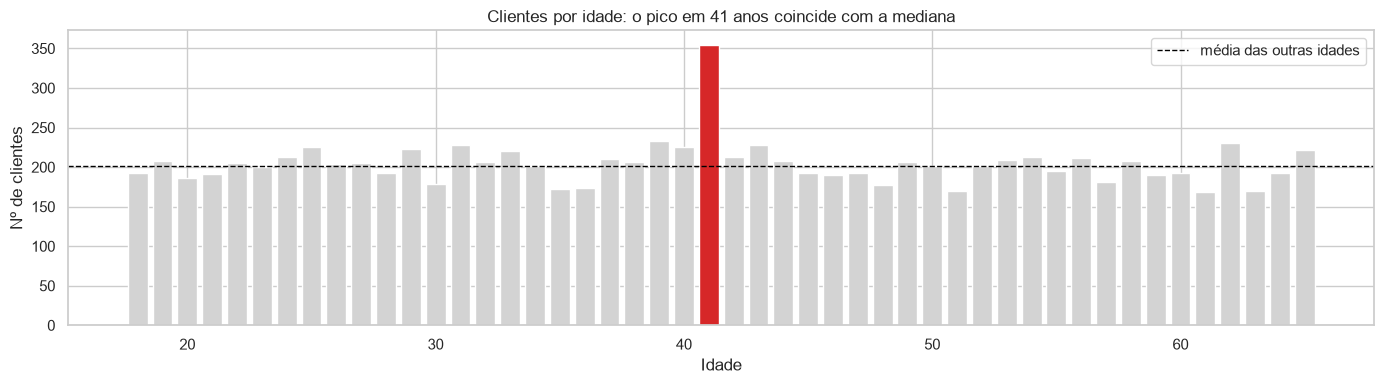

In [12]:
clientes = df.groupby("CustomerID").agg(
    Age=("Age", "first"), City=("City", "first"), CustomerSegment=("CustomerSegment", "first"),
    SignupDate=("SignupDate", "first"), n_pedidos=("OrderID", "size"), gasto_total=("Sales", "sum"),
)

cont_idade = clientes["Age"].value_counts().sort_index()
media_outras = cont_idade.drop(41).mean()
print(f"Mediana da idade (clientes): {clientes['Age'].median():.0f}")
print(f"Clientes com 41 anos: {cont_idade[41]} | média das demais idades: {media_outras:.0f}")
print(f"Excesso aproximado em 41 anos: {cont_idade[41] - media_outras:.0f} clientes")

cores = [COR_ALERTA if idade == 41 else COR_NEUTRA for idade in cont_idade.index]
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(cont_idade.index, cont_idade.values, color=cores)
ax.axhline(media_outras, color="black", linestyle="--", linewidth=1, label="média das outras idades")
ax.set_title("Clientes por idade: o pico em 41 anos coincide com a mediana")
ax.set_xlabel("Idade"); ax.set_ylabel("Nº de clientes"); ax.legend()
plt.tight_layout(); plt.show()

**Leitura:** a distribuição de idades é quase **uniforme** entre 18 e 65, com cerca de 200 clientes por idade, **exceto em 41 anos, que tem ~355**. E 41 é exatamente a mediana. Esse é o padrão típico de **imputação pela mediana**: aproximadamente 150 clientes provavelmente tinham idade ausente e receberam o valor 41.

Não dá para saber *quais* dos clientes com 41 anos são reais e quais foram imputados. Para decidir como tratar, precisamos entender o mecanismo.

#### 2.2 Datas: cadastro depois da compra?

In [13]:
df["cadastro_inconsistente"] = df["SignupDate"] > df["OrderDate"]
print(f"Pedidos com cadastro POSTERIOR à compra: {df['cadastro_inconsistente'].sum()} ({df['cadastro_inconsistente'].mean():.1%})")
dias = (df["OrderDate"] - df["SignupDate"]).dt.days
print(f"Diferença pedido − cadastro: mín = {dias.min()} dias | máx = {dias.max()} dias")

Pedidos com cadastro POSTERIOR à compra: 13773 (28.0%)
Diferença pedido − cadastro: mín = -722 dias | máx = 1272 dias


**Leitura:** **28% dos pedidos** foram feitos antes de o cliente se cadastrar, com até ~2 anos de antecedência. Não é outlier: é uma **violação lógica** numa fração enorme da base. Na prática, `SignupDate` é uma coluna sem informação confiável. Qualquer métrica de "tempo de casa do cliente" calculada com ela seria ruído.

#### Identificando o mecanismo

**As ausências ocorrem juntas?** Mesmo teste da aula: se "idade provavelmente imputada" e "cadastro inconsistente" aparecem nas mesmas linhas, isso aponta para uma falha sistemática única, como um lote de dados ruim.

Aqui o volume é grande (milhares de linhas), então além da contagem bruta o Qui-Quadrado tem poder suficiente para ser informativo.

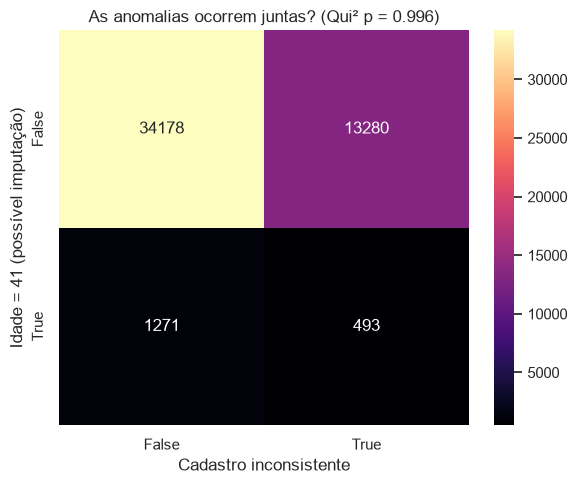

cadastro_inconsistente  False  True 
idade_41                            
False                   0.720  0.280
True                    0.721  0.279


In [14]:
df["idade_41"] = df["Age"] == 41
tab = pd.crosstab(df["idade_41"], df["cadastro_inconsistente"],
                  rownames=["Idade = 41 (possível imputação)"], colnames=["Cadastro inconsistente"])
p = stats.chi2_contingency(tab)[1]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tab, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"As anomalias ocorrem juntas? (Qui² p = {p:.3f})")
plt.tight_layout(); plt.show()
print(pd.crosstab(df["idade_41"], df["cadastro_inconsistente"], normalize="index").round(3))

Um segundo teste de mecanismo: se a imputação de idade fosse **MAR** (dependente de algo observado), os clientes com 41 anos teriam um perfil diferente (outra cidade, outro segmento, outro desfecho). Se for **MCAR**, o perfil deve ser igual ao do restante.

In [15]:
resultado = []
for col in ["City", "CustomerSegment", "PaymentMethod", "Category", "desfecho"]:
    p = stats.chi2_contingency(pd.crosstab(df["idade_41"], df[col]))[1]
    resultado.append({"variavel": col, "p_valor_qui2": round(p, 4), "perfil_diferente (α=0.05)": p < 0.05})
pd.DataFrame(resultado).set_index("variavel")

,p_valor_qui2,perfil_diferente (α=0.05)
variavel,,
City,0.1104,False
CustomerSegment,0.6019,False
PaymentMethod,0.9943,False
Category,0.4928,False
desfecho,0.7153,False


**Discussão sobre o mecanismo (MCAR / MAR / MNAR):**

- **Idade imputada:** os pedidos com idade 41 **não** diferem do restante em cidade, segmento, pagamento, categoria ou desfecho. Isso é compatível com **MCAR**. **MNAR** (a idade faltar *por causa* do próprio valor, como clientes mais velhos que não informam a idade) não pode ser descartado só com os dados, porque o valor real sumiu. Mas como o formato da distribuição continua uniforme fora do pico, não há sinal de que uma faixa específica tenha "desaparecido".
- **Cadastro inconsistente:** também não se concentra em nenhum grupo e é independente da idade imputada. Parece um defeito da **coluna** (geração ou importação da data), não de um subconjunto de clientes.
- **Linhas removidas (778 pedidos, 180 clientes):** esse é o ponto cego. Não sabemos o critério da limpeza original. Se, por exemplo, pedidos com problema de pagamento foram descartados, a taxa de problema observada estaria **subestimada** (seleção/MNAR). Não há como testar isso com o arquivo recebido. O certo é **declarar a limitação**, não "resolver".

## 3. Princípio Distribucional

Ainda com os dados **originais**, calculamos o retrato "antes" para orientar o tratamento.

In [16]:
VARS_QUANT = ["Age", "Quantity", "Discount", "UnitPrice", "Sales"]
VARS_QUALI = ["PaymentMethod", "Status", "City", "CustomerSegment", "Category"]

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,41.28,41.00,13.68,18.00,65.00,0.03,-1.16
Quantity,1.88,2.00,1.08,-2.00,5.00,1.14,0.58
Discount,7.49,5.00,7.75,0.00,30.00,1.05,0.68
UnitPrice,40.29,28.00,42.61,7.00,260.00,2.67,9.36
Sales,69.99,38.00,94.48,-170.00,1300.00,4.10,26.53


**Discussão:** quais variáveis são assimétricas (skew > 1) ou têm cauda pesada (|kurtosis| > 2)?

- **`Sales`** (skew ≈ 4,1; kurt ≈ 26,5) e **`UnitPrice`** (skew ≈ 2,7; kurt ≈ 9,4) têm cauda direita longa. Faz sentido para preço: há muitos itens baratos (cabos, capinhas, cadernos) e poucos caros (tablet, cadeira de escritório).
- **`Quantity`** e **`Discount`** têm skew ≈ 1,1 e 1,0. São discretas e concentradas nos valores baixos (1 unidade, 0% de desconto).
- **`Age`** tem skew ≈ 0 e **curtose ≈ −1,15**. Uma distribuição uniforme tem curtose de −1,2, então a idade é praticamente **uniforme** de 18 a 65. Isso é pouco realista para clientes de e-commerce, que costumam se concentrar entre 20 e 40 anos, e é o primeiro indício de que a base pode ser **sintética**.

### Distribuições de dados

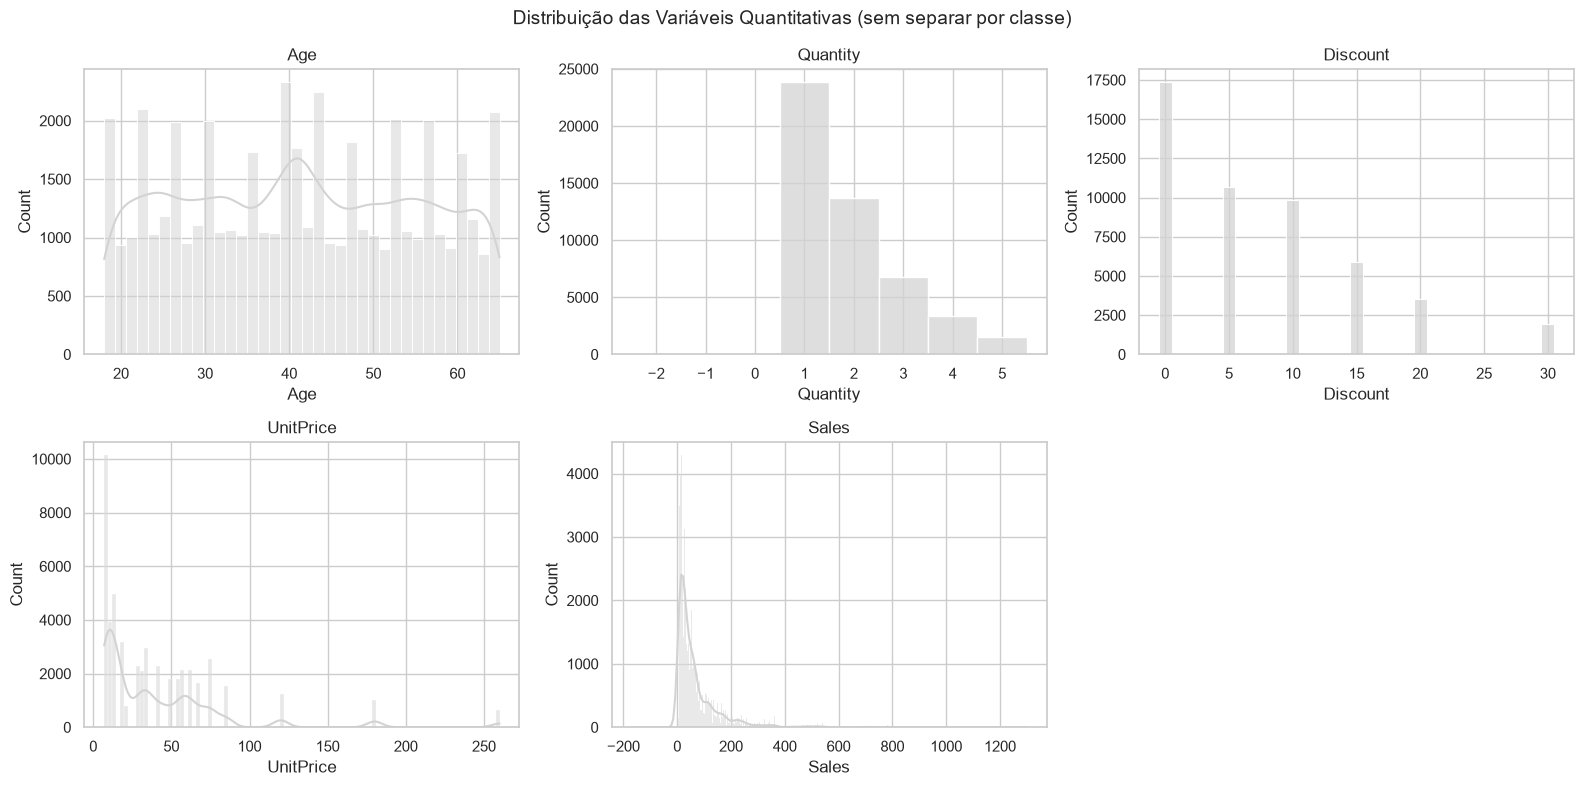

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
for i, col in enumerate(VARS_QUANT):
    discreta = df[col].nunique() <= 12
    sns.histplot(data=df, x=col, kde=not discreta, discrete=discreta, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
axes[-1].axis("off")
fig.suptitle("Distribuição das Variáveis Quantitativas (sem separar por classe)", fontsize=14)
plt.tight_layout(); plt.show()

Com 92% dos pedidos concluídos, um histograma de **contagem** por classe deixaria o painel "Problema" com barras quase invisíveis. Por isso usamos `stat="density"`, que compara o **formato** das distribuições, e não o tamanho dos grupos.

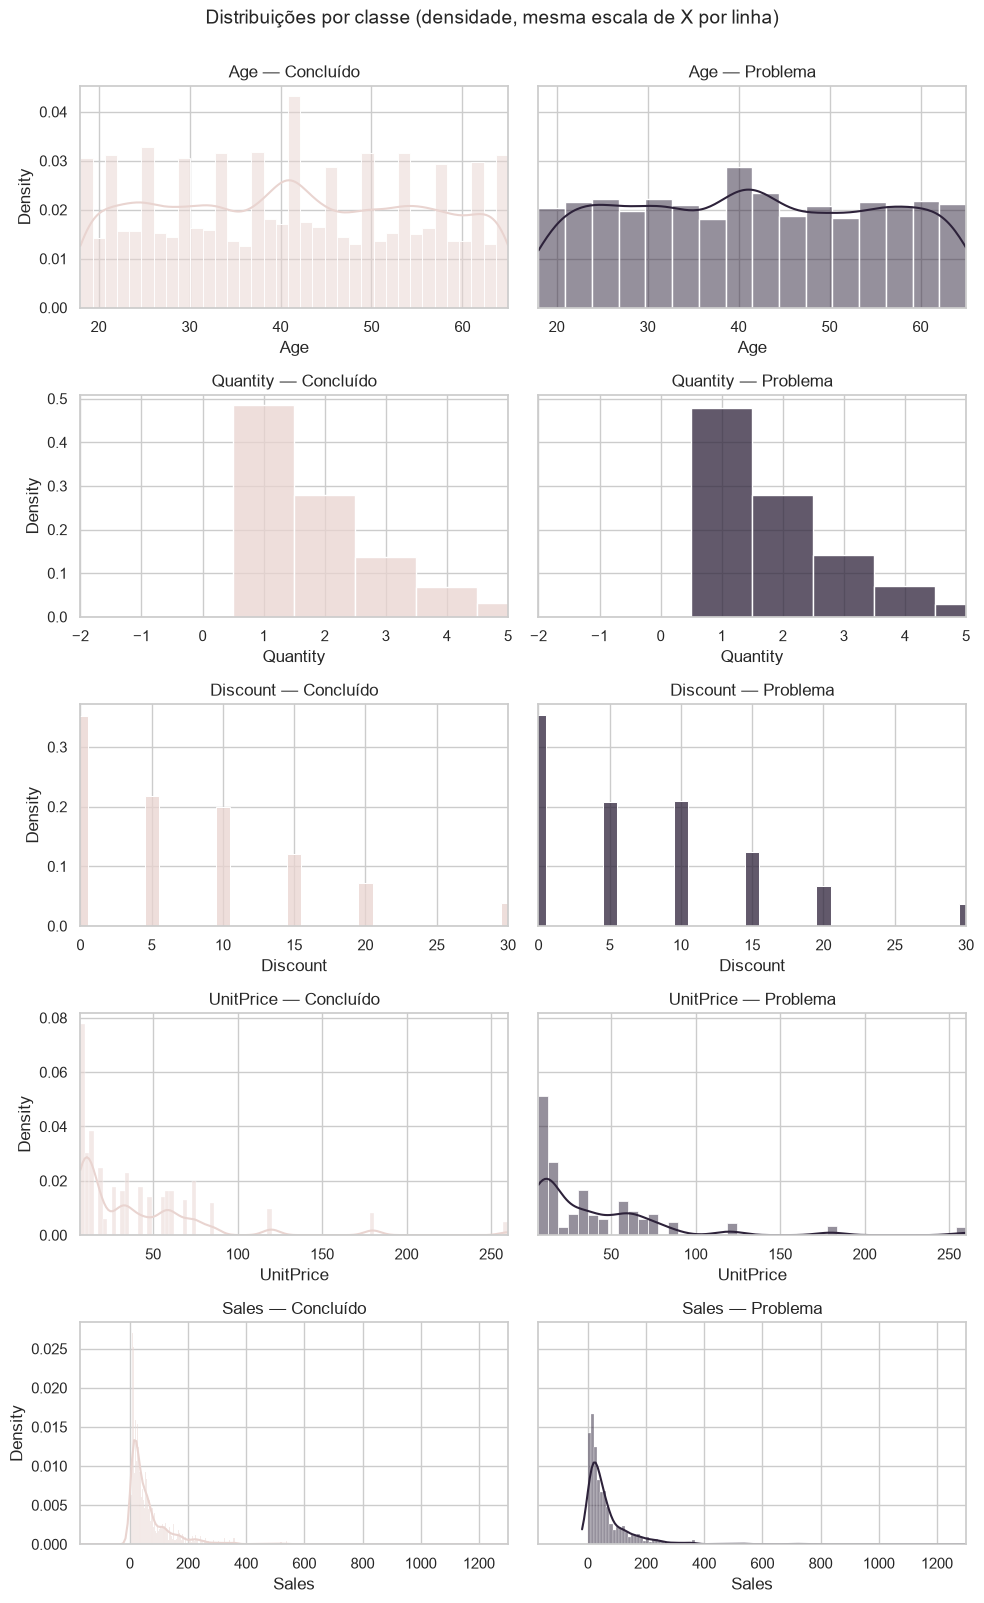

In [18]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.2 * len(VARS_QUANT)), sharey="row")
for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    discreta = df[col].nunique() <= 12
    for j, classe in enumerate(["Concluído", "Problema"]):
        sub = df[df["desfecho"] == classe]
        sns.histplot(data=sub, x=col, stat="density", discrete=discreta, kde=not discreta,
                     color=PALETA[classe], ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")
fig.suptitle("Distribuições por classe (densidade, mesma escala de X por linha)", fontsize=14, y=1.001)
plt.tight_layout(); plt.show()

**Discussão:** alguma variável tem formato bem diferente entre "Concluído" e "Problema"?

*Resposta:* **não.** Os pares de painéis são praticamente idênticos em todas as variáveis. Visualmente, nem valor, nem quantidade, nem desconto, nem idade parecem diferenciar pedidos com problema. A análise bivariada vai testar isso formalmente.

#### Testes de Aderência

*O valor do pedido (`Sales`) segue uma distribuição normal?*

**Atenção ao tamanho da amostra:** a aula alertou que amostras muito grandes deixam o teste sensível demais. Além disso, o Shapiro-Wilk do SciPy só é confiável até **n = 5.000**, e aqui temos ~49 mil linhas. Por isso:

- **Shapiro-Wilk** em uma subamostra aleatória de 5.000;
- **Anderson-Darling** na base inteira (não tem esse limite);
- **QQ-Plot** como evidência visual.

Shapiro-Wilk (amostra n=5000) — Sales: W = 0.6259, p = 5.29e-74
Anderson-Darling (n=49222) — Sales: A² = 4806.2 | valor crítico 5% = 0.752
Rejeita normalidade? Sim


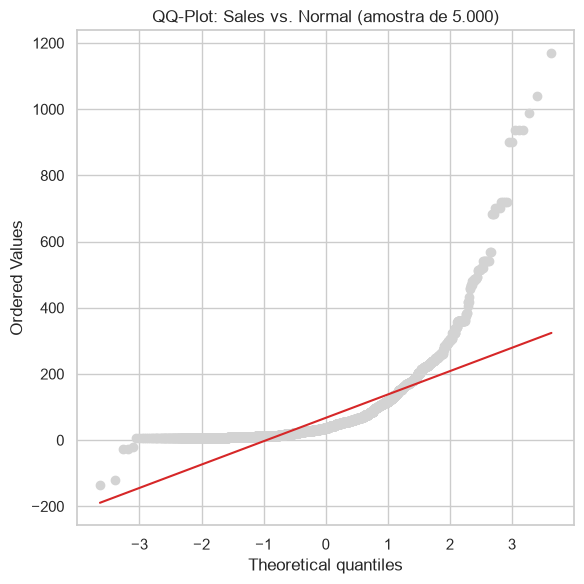

In [19]:
amostra = df.sample(5000, random_state=42)

stat_sw, p_sw = stats.shapiro(amostra["Sales"])
ad = stats.anderson(df["Sales"], dist="norm")
print(f"Shapiro-Wilk (amostra n=5000) — Sales: W = {stat_sw:.4f}, p = {p_sw:.3g}")
print(f"Anderson-Darling (n={len(df)}) — Sales: A² = {ad.statistic:.1f} | valor crítico 5% = {ad.critical_values[2]:.3f}")
print("Rejeita normalidade?", "Sim" if (p_sw < 0.05 and ad.statistic > ad.critical_values[2]) else "Não")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(amostra["Sales"], dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Sales vs. Normal (amostra de 5.000)")
plt.tight_layout(); plt.show()

In [20]:
resultados_normalidade = []
for col in VARS_QUANT:
    _, p = stats.shapiro(amostra[col])
    a = stats.anderson(df[col], dist="norm")
    resultados_normalidade.append({
        "variavel": col, "shapiro_p (n=5000)": f"{p:.2e}",
        "anderson_A2": round(a.statistic, 1), "critico_5%": round(a.critical_values[2], 3),
        "rejeita_normalidade": (p < 0.05) and (a.statistic > a.critical_values[2]),
    })
pd.DataFrame(resultados_normalidade).set_index("variavel")

,shapiro_p (n=5000),anderson_A2,critico_5%,rejeita_normalidade
variavel,,,,
Age,1.95e-36,487.7,0.752,True
Quantity,2.91e-63,4098.4,0.752,True
Discount,6.84e-57,2368.4,0.752,True
UnitPrice,1.46e-68,3335.2,0.752,True
Sales,5.29e-74,4806.2,0.752,True


**Leitura:** as três evidências concordam, e **todas** as variáveis rejeitam normalidade com folga. O QQ-Plot de `Sales` sobe em "degraus" (valores discretos de preço × quantidade) e se curva forte na cauda direita.

Um detalhe de interpretação: `Age` também rejeita, mas não por assimetria. O motivo é ter **cauda leve demais** (uniforme). "Não normal" pode significar formatos muito diferentes, e é por isso que o teste sozinho não substitui olhar o gráfico.

**Consequência para o resto do notebook:** correlação de **Spearman** e testes **não-paramétricos** (Mann-Whitney, Kruskal-Wallis) serão os resultados principais.

**ECDF — Sales por desfecho**

`Sales` vai de ~5 a 1.300, e na escala linear toda a ação ficaria espremida à esquerda. Usamos eixo X **logarítmico** (só nos valores positivos, já que log de negativo não existe).

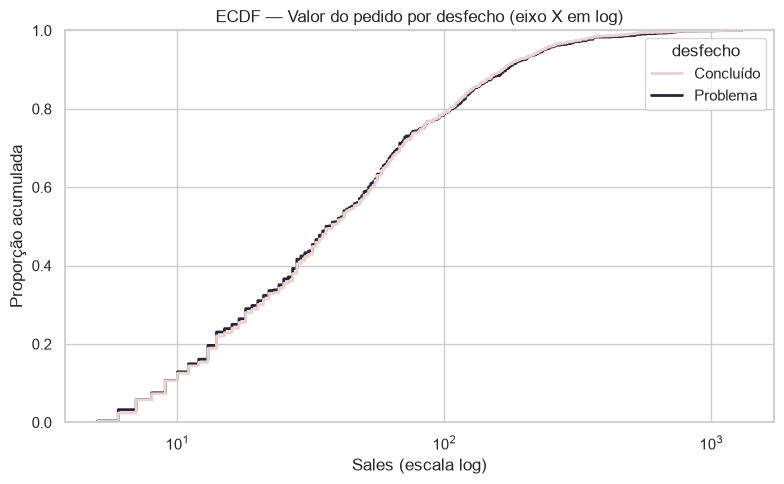

In [21]:
positivos = df[df["Sales"] > 0]
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=positivos, x="Sales", hue="desfecho", palette=PALETA, linewidth=2)
plt.xscale("log")
plt.title("ECDF — Valor do pedido por desfecho (eixo X em log)")
plt.xlabel("Sales (escala log)"); plt.ylabel("Proporção acumulada")
plt.tight_layout(); plt.show()

**Como ler:** as duas curvas estão **sobrepostas** em toda a faixa. Em nenhum valor de pedido a proporção acumulada de "Problema" se afasta da de "Concluído". Pedidos caros não dão mais problema que pedidos baratos.

### Métricas de Tendência Central

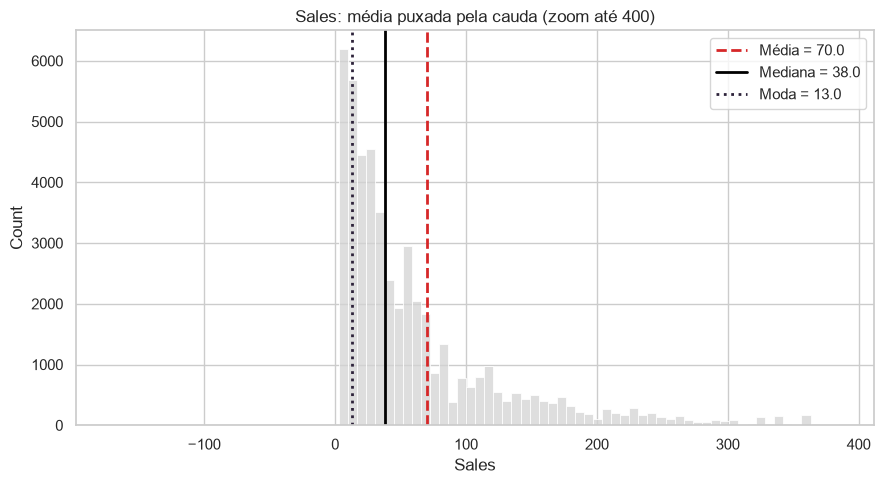

In [22]:
media, mediana, moda = df["Sales"].mean(), df["Sales"].median(), df["Sales"].mode()[0]

plt.figure(figsize=(9, 5))
sns.histplot(data=df[df["Sales"] <= 400], x="Sales", bins=80, color=COR_NEUTRA)
plt.axvline(media, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media:.1f}")
plt.axvline(mediana, color="black", linewidth=2, label=f"Mediana = {mediana:.1f}")
plt.axvline(moda, color=COR_DESTAQUE, linestyle=":", linewidth=2, label=f"Moda = {moda:.1f}")
plt.title("Sales: média puxada pela cauda (zoom até 400)")
plt.legend(); plt.tight_layout(); plt.show()

A média (~70) fica quase **o dobro** da mediana (38). Um pedido "típico" vale ~38, e a média é inflada pelos poucos pedidos grandes. Para resumir o valor de pedido desta loja, a **mediana** é a medida honesta.

### Dispersão

In [23]:
dispersao = df[VARS_QUANT].agg(["var", "std", "mean"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao["CV (std/média)"] = dispersao["std"] / dispersao["mean"]
dispersao.drop(columns="mean").round(2)   # última expressão da célula, então a tabela aparece

,var,std,IQR,CV (std/média)
Age,187.18,13.68,24.0,0.33
Quantity,1.17,1.08,1.0,0.57
Discount,60.13,7.75,10.0,1.04
UnitPrice,1815.87,42.61,47.0,1.06
Sales,8927.09,94.48,67.0,1.35


O **coeficiente de variação** permite comparar variáveis de escalas diferentes. `Sales` (CV ≈ 1,35) e `UnitPrice` (≈ 1,06) têm desvio-padrão **maior que a própria média**, que é o sinal clássico de cauda longa. `Age` (CV ≈ 0,33) é a mais "comportada".

### Boxplot e violin plot por classe

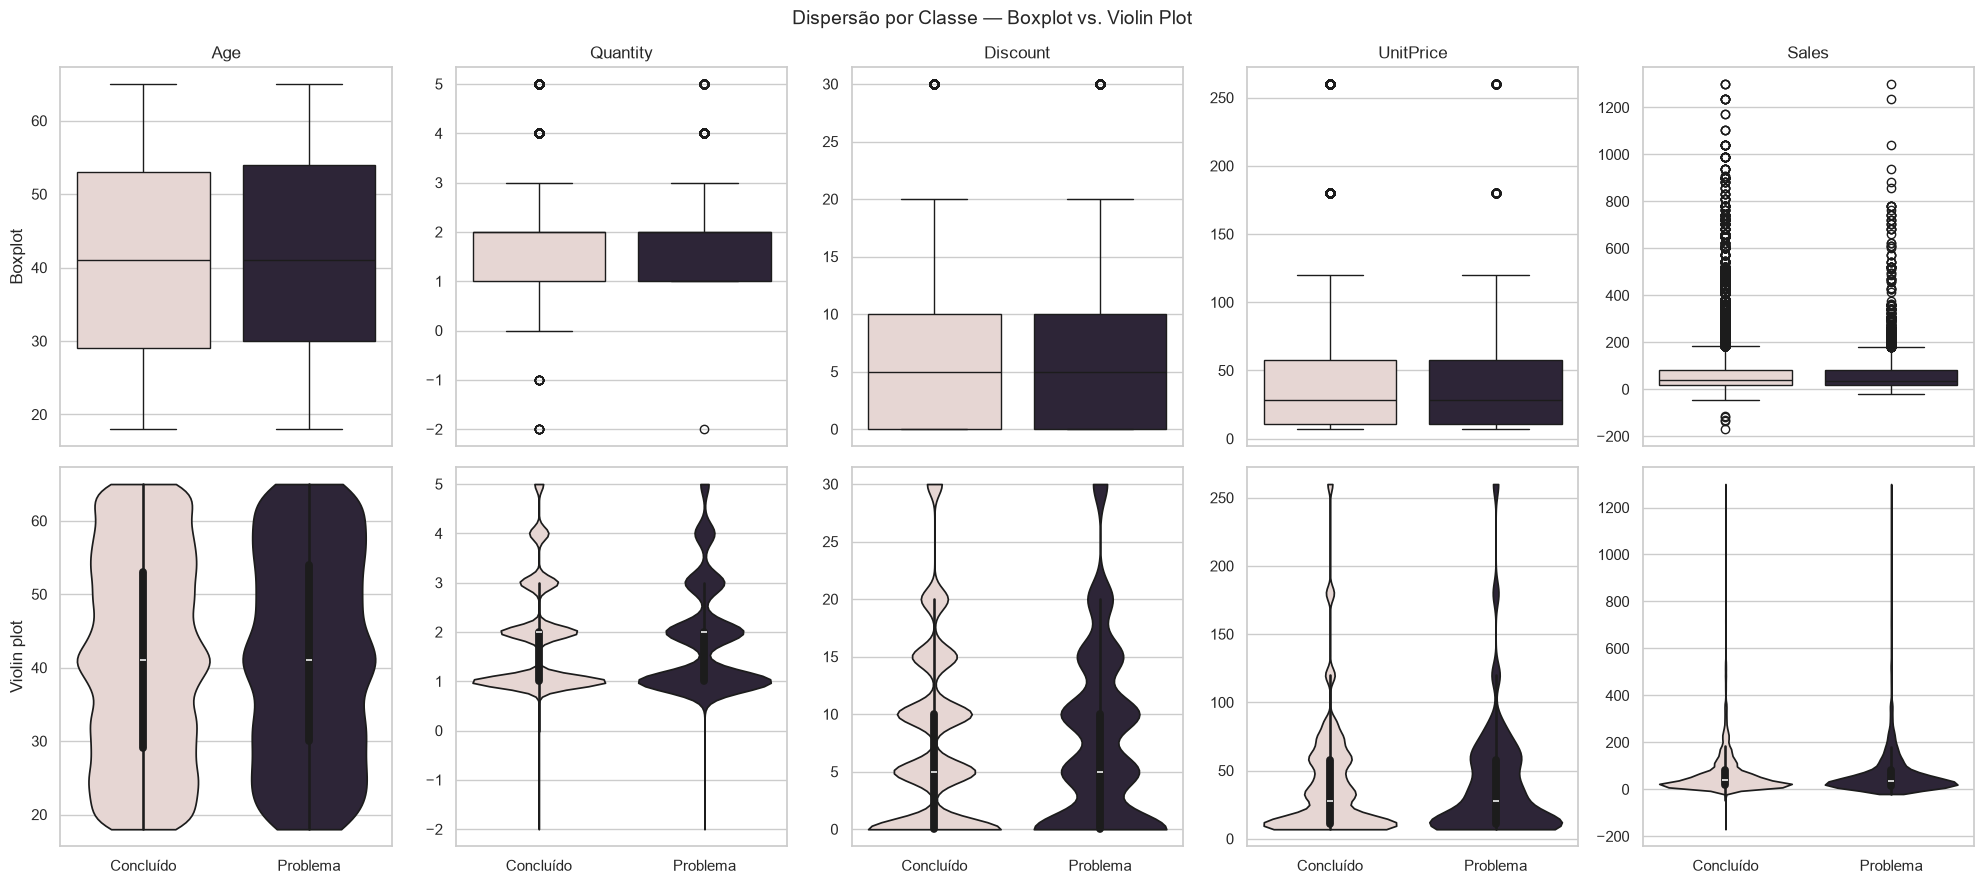

In [24]:
fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")
for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="desfecho", y=col, hue="desfecho", palette=PALETA, legend=False, ax=axes[0, i])
    sns.violinplot(data=df, x="desfecho", y=col, hue="desfecho", palette=PALETA, legend=False, cut=0, ax=axes[1, i])
    axes[0, i].set_title(col); axes[0, i].set_xlabel(""); axes[1, i].set_xlabel("")
    axes[0, i].set_ylabel(""); axes[1, i].set_ylabel("")
axes[0, 0].set_ylabel("Boxplot"); axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout(); plt.show()

**Discussão:** alguma caixa é nitidamente mais alta ou mais baixa entre as classes?

*Resposta:* não. Medianas, IQRs e formatos dos violinos coincidem nas cinco variáveis. O que chama atenção é outra coisa: a quantidade de pontos acima do bigode em `Sales`, `UnitPrice` e `Quantity`, e os valores **negativos** de `Quantity` e `Sales`. Isso leva direto à Seção 4.

## 4. Tratamento de Dados Ausentes e Outliers

Com o retrato "antes" em mãos, decidimos o tratamento de cada problema **pelo tipo**, e não aplicando uma regra única.

### Detecção de Outliers por IQR

Regra clássica: outlier é qualquer ponto fora de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.

In [25]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    li, ls = limites_iqr(df[col])
    n = int(((df[col] < li) | (df[col] > ls)).sum())
    resumo_outliers[col] = {"limite_inferior": round(li, 2), "limite_superior": round(ls, 2),
                            "n_outliers": n, "%_da_base": round(100 * n / len(df), 2)}
pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers,%_da_base
Age,-7.0,89.0,0.0,0.00
Quantity,-0.5,3.5,4919.0,9.99
Discount,-15.0,25.0,1922.0,3.90
UnitPrice,-59.5,128.5,1691.0,3.44
Sales,-83.5,184.5,3884.0,7.89


### Visualizando os Outliers

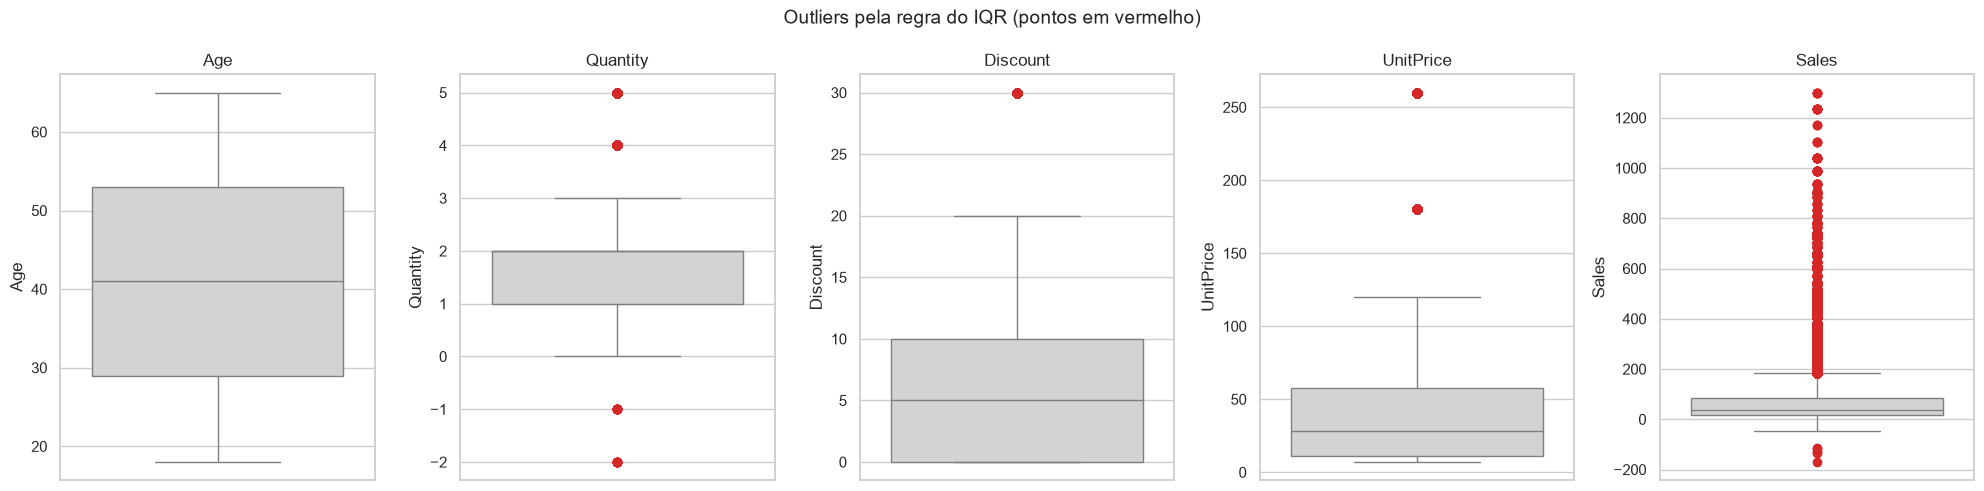

In [26]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))
for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"), ax=axes[i])
    axes[i].set_title(col)
fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout(); plt.show()

### Classificando os outliers (Estatístico / De domínio / Erro de dados)

Contar outliers não basta. Precisamos olhar **quem** eles são.

In [27]:
li, ls = limites_iqr(df["Sales"])
print("Produtos nos pedidos marcados como outlier de Sales (acima do limite superior):")
print(df.loc[df["Sales"] > ls, "ProductName"].value_counts().head(8), "\n")

print("Pedidos com Quantity <= 0:")
invalidos = df[df["Quantity"] <= 0]
print(invalidos["Quantity"].value_counts().sort_index())
print("Status desses pedidos:", invalidos["Status"].value_counts().to_dict())

Produtos nos pedidos marcados como outlier de Sales (acima do limite superior):
ProductName
Tablet                 649
Smart Watch            617
Headphones             573
Office Chair           549
Microphone             371
Mechanical Keyboard    311
Gaming Controller      304
Bluetooth Speaker      206
Name: count, dtype: int64 

Pedidos com Quantity <= 0:
Quantity
-2.0     9
-1.0    10
 0.0     5
Name: count, dtype: int64
Status desses pedidos: {'Completed': 23, 'Cancelled': 1}


Um produto merece investigação à parte. Olhando a tabela de preços, o **Monitor custa 21**, menos que um mouse sem fio (18) somado a um cabo HDMI (11). Para confirmar que é anomalia e não impressão, comparamos preço, volume e quantidade típica por produto.

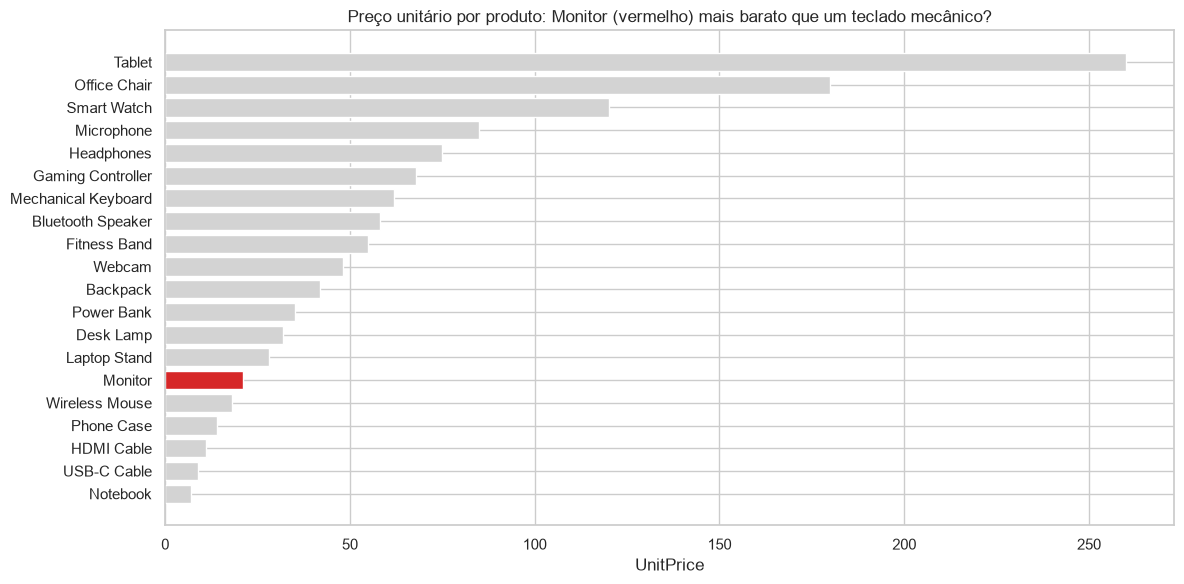

,Category,preco,pedidos,qtd_max
ProductName,,,,
Monitor,Electronics,21.0,786,3.0
Office Chair,Home Office,180.0,1033,5.0
Tablet,Electronics,260.0,658,5.0
Mechanical Keyboard,Electronics,62.0,2153,5.0
HDMI Cable,Accessories,11.0,3932,5.0


In [28]:
por_produto = (df.groupby(["ProductName", "Category"])
                 .agg(preco=("UnitPrice", "first"), pedidos=("OrderID", "size"), qtd_max=("Quantity", "max"))
                 .reset_index().sort_values("preco"))

cores = [COR_ALERTA if p == "Monitor" else COR_NEUTRA for p in por_produto["ProductName"]]
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(por_produto["ProductName"], por_produto["preco"], color=cores)
ax.set_title("Preço unitário por produto: Monitor (vermelho) mais barato que um teclado mecânico?")
ax.set_xlabel("UnitPrice")
plt.tight_layout(); plt.show()

por_produto.set_index("ProductName").loc[["Monitor", "Office Chair", "Tablet", "Mechanical Keyboard", "HDMI Cable"]]

**Discussão, variável por variável:**

| Achado | Tipo | Evidência | Decisão |
|---|---|---|---|
| `Quantity` ≤ 0 (24 pedidos) | **Erro de dados** | Quantidade negativa ou zero, 23 delas com status *Completed*. Não é devolução, porque devoluções têm status próprio. | **Remover** (0,05% da base, e não há como corrigir) |
| `Quantity` = 4 ou 5 (~10% da base) | **Falha do detector** | Q1 = 1 e Q3 = 2 geram limite de 3,5. Numa variável discreta de 5 níveis, a regra marca como "atípico" um décimo dos pedidos, que são compras normais. | **Manter** |
| `Sales` alto (~8%) | **Estatístico** | São Tablet, Smart Watch, Headphones e Office Chair em quantidades maiores, ou seja, produtos reais do catálogo. | **Manter** (e são os pedidos mais valiosos) |
| `UnitPrice` alto (~3%) | **Estatístico** | Só Tablet (260) e Office Chair (180). A variável tem 20 valores, um por produto. | **Manter** |
| **Monitor a 21** | **De domínio** | O preço não bate com a categoria. O Monitor tem só 786 pedidos e nunca passa de 3 unidades por pedido, padrão de item **caro** como o Tablet. Hipótese: um zero perdido (210 em vez de 21). | **Investigar.** Sem acesso à fonte, **manter e sinalizar**. Não se corrige preço com base em palpite. |
| Idade = 41 (~150 clientes a mais) | **Ausente disfarçado** | Pico exatamente na mediana, com mecanismo compatível com MCAR (Seção 2). | **Manter**, sem como separar real de imputado, e rodar **análise de sensibilidade** no fairness |
| Cadastro após o pedido (28%) | **Erro de dados** | Violação lógica. | **Manter as linhas**, sinalizar e **não usar** `SignupDate`. Remover 28% da base por um defeito de *uma* coluna trocaria um problema pequeno por um grande. |
| `OrderValue` | **Redundância** | Idêntica a `Sales`. | **Remover a coluna** |

### Aplicando o tratamento

In [29]:
df_antes = df.copy()
linhas_antes = len(df)

df = df[df["Quantity"] > 0].reset_index(drop=True)
df = df.drop(columns=["OrderValue"])
df["produto_suspeito"] = df["ProductName"] == "Monitor"

print(f"Linhas antes: {linhas_antes} | depois: {len(df)} | removidas: {linhas_antes - len(df)}")
print(f"Flags mantidas para rastreabilidade: cadastro_inconsistente = {df['cadastro_inconsistente'].sum()}, "
      f"idade_41 = {df['idade_41'].sum()}, produto_suspeito = {df['produto_suspeito'].sum()}")

Linhas antes: 49222 | depois: 49198 | removidas: 24
Flags mantidas para rastreabilidade: cadastro_inconsistente = 13767, idade_41 = 1763, produto_suspeito = 786


Como na aula, ilustramos uma transformação logarítmica em `Sales`, útil caso um teste ou modelo mais adiante sofra com a assimetria. Ela não será usada nas próximas seções.

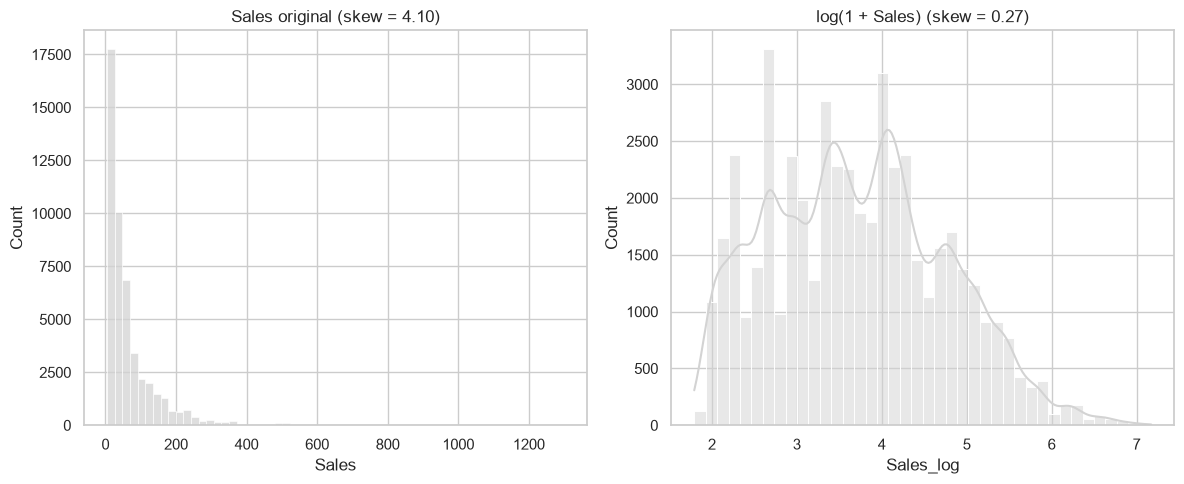

In [30]:
df["Sales_log"] = np.log1p(df["Sales"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="Sales", bins=60, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Sales original (skew = {df['Sales'].skew():.2f})")
sns.histplot(data=df, x="Sales_log", bins=40, kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Sales) (skew = {df['Sales_log'].skew():.2f})")
plt.tight_layout(); plt.show()

**Discussão:** a transformação log leva a assimetria de ~4,1 para perto de zero. Ela resolve o formato, mas não os "degraus" da variável discreta, então ainda não seria normal.

## 5. Estatística Descritiva pt. 2

Fechando o ciclo: mesma bateria da Seção 3, agora nos dados tratados.

In [31]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()
(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"}).round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,41.28,41.00,13.68,18.00,65.00,0.03,-1.16
Quantity,1.88,2.00,1.08,1.00,5.00,1.15,0.56
Discount,7.49,5.00,7.75,0.00,30.00,1.05,0.68
UnitPrice,40.29,28.00,42.61,7.00,260.00,2.67,9.37
Sales,70.04,38.00,94.47,5.00,1300.00,4.10,26.55


### Comparando "antes" x "depois"

In [32]:
comparacao = pd.DataFrame({
    "min_antes": desc["min"], "min_depois": desc_depois["min"],
    "skew_antes": desc["skewness"], "skew_depois": desc_depois["skewness"],
    "kurt_antes": desc["kurtosis"], "kurt_depois": desc_depois["kurtosis"],
})
comparacao["delta_skew"] = comparacao["skew_depois"] - comparacao["skew_antes"]
comparacao["delta_kurt"] = comparacao["kurt_depois"] - comparacao["kurt_antes"]
comparacao.round(3)

,min_antes,min_depois,skew_antes,skew_depois,kurt_antes,kurt_depois,delta_skew,delta_kurt
Age,18.0,18.0,0.027,0.027,-1.155,-1.155,0.000,0.000
Quantity,-2.0,1.0,1.139,1.154,0.582,0.561,0.016,-0.021
Discount,0.0,0.0,1.048,1.048,0.677,0.677,0.000,0.000
UnitPrice,7.0,7.0,2.670,2.671,9.364,9.366,0.000,0.002
Sales,-170.0,5.0,4.099,4.103,26.526,26.547,0.004,0.021


**Discussão:** skewness e curtose quase não mudaram, com deltas na segunda ou terceira casa decimal. Isso era esperado: removemos 24 linhas de ~49 mil e não mexemos em nenhum outlier legítimo. A mudança que importa está nos **mínimos**: `Quantity` passou de −2 para 1 e `Sales` de −170 para um valor positivo. O tratamento eliminou o que era **impossível** sem distorcer o que é **real**.

**`Sales` ainda rejeita normalidade?**

In [33]:
ad_depois = stats.anderson(df["Sales"], dist="norm")
print(f"Anderson-Darling (antes)  — Sales: A² = {ad.statistic:.1f}")
print(f"Anderson-Darling (depois) — Sales: A² = {ad_depois.statistic:.1f} | crítico 5% = {ad_depois.critical_values[2]:.3f}")

Anderson-Darling (antes)  — Sales: A² = 4806.2
Anderson-Darling (depois) — Sales: A² = 4809.3 | crítico 5% = 0.752


**Visualizando antes x depois, lado a lado**

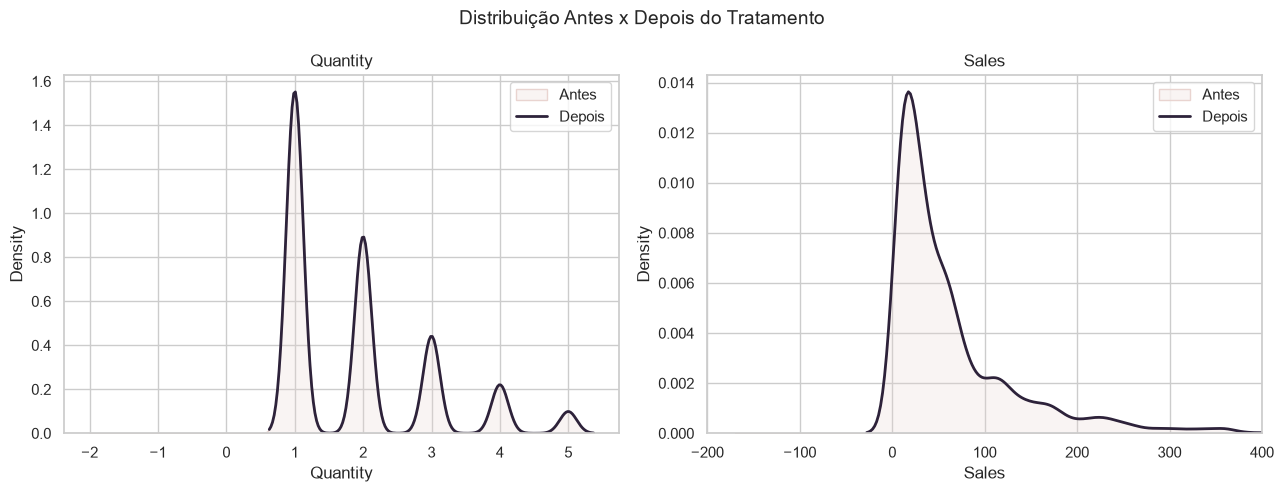

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col in zip(axes, ["Quantity", "Sales"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax, clip=(df_antes[col].min(), 400))
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=False, linewidth=2, label="Depois", ax=ax, clip=(df_antes[col].min(), 400))
    ax.set_title(col); ax.legend()
axes[1].set_xlim(-200, 400)
fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout(); plt.show()

As curvas se sobrepõem. A remoção de 24 linhas é invisível na densidade, e o ganho está na **validade** dos dados, não no formato. É a confirmação de um tratamento conservador.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

#### Frequências absolutas e relativas

In [35]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- PaymentMethod ---
               absoluta  relativa
PaymentMethod                    
Gateway           23880     0.485
CardToCard        11739     0.239
Wallet             8658     0.176
Cash               4921     0.100

--- Status ---
           absoluta  relativa
Status                       
Completed     45253     0.920
Cancelled      2437     0.050
Returned       1508     0.031

--- City ---
         absoluta  relativa
City                       
Tehran      13996     0.284
Mashhad      6219     0.126
Karaj        4964     0.101
Isfahan      4911     0.100
Shiraz       4361     0.089
Tabriz       4132     0.084
Ahvaz        2921     0.059
Rasht        2857     0.058
Kerman       2464     0.050
Qom          2373     0.048

--- CustomerSegment ---
                 absoluta  relativa
CustomerSegment                    
Regular             27282     0.555
New                 17049     0.347
VIP                  4867     0.099

--- Category ---
             absoluta  relativa
Ca

#### Visualizando as frequências

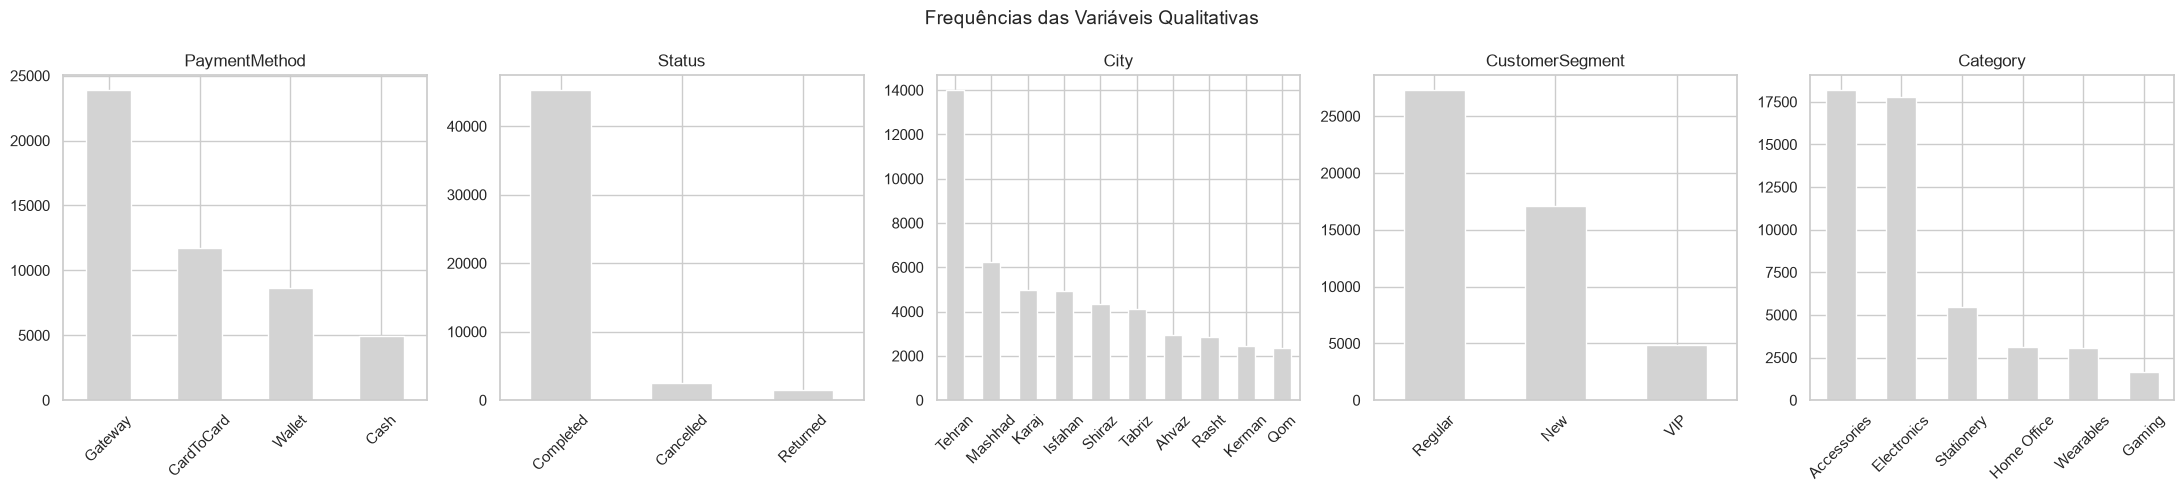

In [36]:
fig, axes = plt.subplots(1, len(VARS_QUALI), figsize=(22, 5))
for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col); axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=45)
fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout(); plt.show()

#### Desbalanceamento entre Classes

In [37]:
def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({"n_classes": n_classes,
                      "razao_desbalanceamento": round(contagens.max() / contagens.min(), 2),
                      "entropia_normalizada": round(ent, 3)})

pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in VARS_QUALI + ["desfecho"]}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
PaymentMethod,4.0,4.85,0.886
Status,3.0,30.01,0.303
City,10.0,5.90,0.926
CustomerSegment,3.0,5.61,0.840
Category,6.0,10.95,0.804
desfecho,2.0,11.47,0.403


**Discussão:**

- **O alvo é o grande desbalanceamento:** 92% concluído vs. 8% problema (razão ≈ 11,5 e entropia ≈ 0,40). Em `Status`, *Completed* supera *Returned* em 30 vezes. Qualquer modelo que chute "Concluído" sempre acertaria 92%, então acurácia não serviria como métrica.
- **`City`:** Teerã concentra 28% dos pedidos, o que é coerente com ser a maior cidade do país. Mesmo assim a entropia é alta (0,93), já que as outras 9 cidades dividem o restante de forma razoável.
- **`Category`:** *Gaming* tem um único produto e só ~3% dos pedidos. Cruzamentos com essa categoria terão menos precisão.

### Análise Bivariada

#### Quantitativa x Quantitativa — Correlação de Spearman

Das três técnicas vistas em aula (Pearson, Spearman e Kendall), escolhemos **Spearman** para este dataset, por três motivos:

1. **Nenhuma variável é normal.** Shapiro-Wilk e Anderson-Darling rejeitaram normalidade em todas (Seção 3). Pearson assume relação linear e é sensível a outliers, e `Sales` tem cauda longa (skew ≈ 4,1) com pedidos de até 1.300.
2. **As relações são monotônicas, mas não lineares.** `Sales` = preço × quantidade × (1 − desconto) é uma relação multiplicativa: quanto maior o preço, maior o valor, mas não em linha reta. Spearman trabalha com a *ordem* dos valores (postos), então captura esse tipo de relação sem exigir linearidade.
3. **Coerência com o resto da análise.** Os testes de comparação usados são não-paramétricos (Mann-Whitney, Kruskal-Wallis), e a matriz multivariada e o correlograma também usam Spearman.

**Por que não Kendall?** Kendall também não exige normalidade e lida bem com valores repetidos, que são muitos aqui (`Quantity` tem 5 níveis e `Discount` tem 6). Mas o τ de Kendall é sistematicamente menor que o ρ de Spearman para a mesma relação, o que torna menos direta a leitura pela escala de interpretação da aula (fraca < 0,3 < moderada < 0,7 < forte). Os dois apontaram as mesmas relações, então Kendall não traria informação nova.

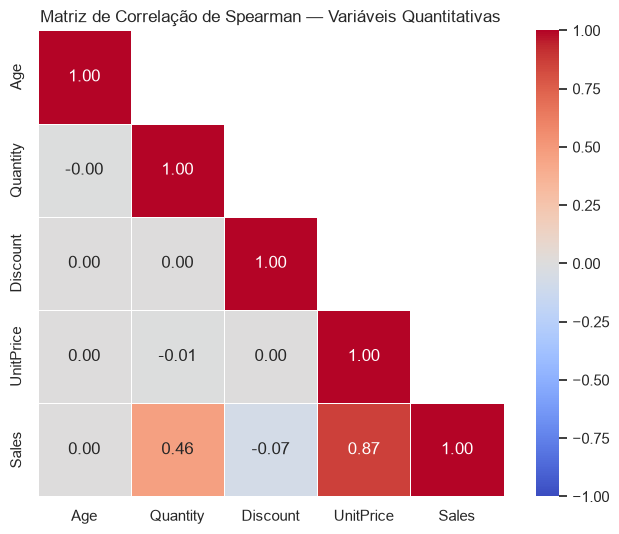

In [38]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")
mask = np.triu(np.ones_like(corr_spearman, dtype=bool), k=1)  # esconde só o triângulo superior (repetido)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_spearman, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Matriz de Correlação de Spearman — Variáveis Quantitativas")
plt.grid(False)
plt.tight_layout()
plt.show()

**Discussão:**

- **`UnitPrice` × `Sales` (ρ = 0,87, forte)** e **`Quantity` × `Sales` (ρ = 0,46, moderada)** são as únicas relações relevantes. Elas confirmam a escolha do método: o Pearson calculado para os mesmos pares dá 0,78 e 0,42, ou seja, subestima as duas porque a relação não é linear. Um tablet (260) comprado em 5 unidades gera um salto que "estica" a reta de Pearson, enquanto Spearman só considera a ordem.
- **Essas correlações existem por construção, não são descobertas.** A Seção 1 mostrou que `Sales` é calculada a partir de preço, quantidade e desconto. Qualquer método mostraria essa relação.
- **Todo o resto é ≈ 0.** Idade não se relaciona com nenhuma variável, e **desconto não aumenta a quantidade comprada (ρ = 0,00)**. Numa loja real, esperaríamos que desconto estimulasse volume. A ausência total dessa relação é mais um indício de que as colunas foram geradas de forma independente, ou seja, de que a base é sintética.
- `Discount` × `Sales` (ρ = −0,07) é negativa e fraca, também por construção: mais desconto reduz um pouco o valor final do pedido.

#### Dispersão entre duas quantitativas

Seguindo a nota da aula ("sem relação de domínio óbvia, escolha o maior |correlação|"), o par é `UnitPrice` × `Sales`. Usamos uma amostra de 4.000 pontos, porque com 49 mil o gráfico vira uma mancha. Também aplicamos um leve *jitter* em X, já que os preços só assumem 20 valores.

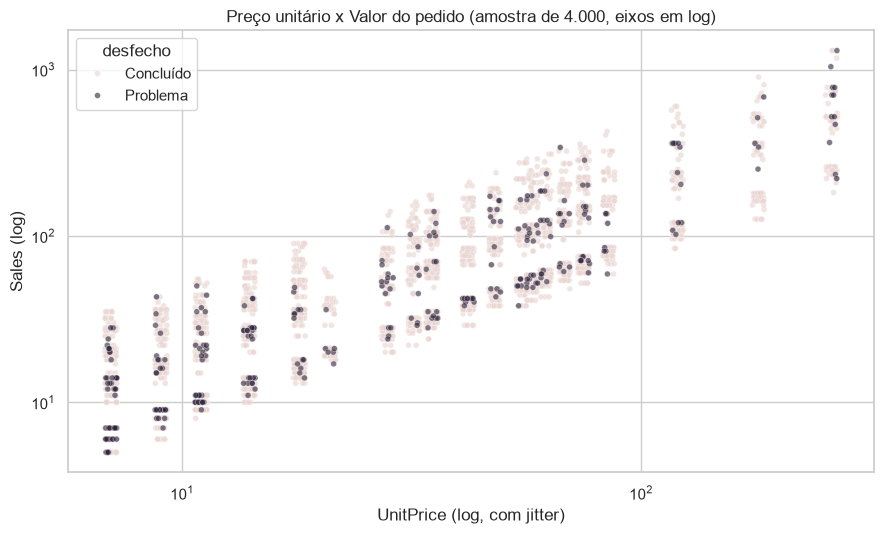

In [39]:
amostra_plot = df.sample(4000, random_state=42).copy()
rng = np.random.default_rng(42)
amostra_plot["UnitPrice_jitter"] = amostra_plot["UnitPrice"] * rng.uniform(0.97, 1.03, len(amostra_plot))

plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=amostra_plot.sort_values("desfecho"), x="UnitPrice_jitter", y="Sales",
                hue="desfecho", palette=PALETA, alpha=0.6, s=18)
plt.xscale("log"); plt.yscale("log")
plt.title("Preço unitário x Valor do pedido (amostra de 4.000, eixos em log)")
plt.xlabel("UnitPrice (log, com jitter)"); plt.ylabel("Sales (log)")
plt.tight_layout(); plt.show()

**Discussão:** a tendência é clara. Cada "coluna" de pontos é um produto, e a subida vertical dentro dela corresponde a quantidade e desconto. **As classes estão completamente misturadas**: nenhuma região do gráfico concentra pedidos com problema.

#### Quantitativa x Qualitativa: Comparando Grupos

**Dois grupos (Concluído vs. Problema):** Mann-Whitney U como resultado principal, com o t-test (Welch) só como contraste.

In [40]:
resultados_comparacao = []
for col in VARS_QUANT:
    g_ok = df.loc[df["desfecho"] == "Concluído", col]
    g_prob = df.loc[df["desfecho"] == "Problema", col]
    _, p_t = stats.ttest_ind(g_ok, g_prob, equal_var=False)
    _, p_u = stats.mannwhitneyu(g_ok, g_prob)
    resultados_comparacao.append({"variavel": col, "mediana_concluido": g_ok.median(), "mediana_problema": g_prob.median(),
                                  "p_valor_ttest": round(p_t, 4), "p_valor_mannwhitney": round(p_u, 4),
                                  "concordam": (p_t < 0.05) == (p_u < 0.05)})
pd.DataFrame(resultados_comparacao).set_index("variavel")

,mediana_concluido,mediana_problema,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,,,
Age,41.0,41.0,0.4063,0.4088,True
Quantity,2.0,2.0,0.6001,0.4730,True
Discount,5.0,5.0,0.8295,0.9819,True
UnitPrice,28.0,28.0,0.8446,0.1816,True
Sales,38.0,36.0,0.3484,0.3482,True


**Discussão:** **nenhuma** variável difere entre as classes (todos os p > 0,05), e os dois testes concordam.

Aqui vale a nota de interpretação da aula. Com ~49 mil linhas, o teste tem **poder enorme**: detectaria até diferenças minúsculas. Então **não rejeitar H₀ aqui não é "falta de amostra"**. É evidência substantiva de que, se existe diferença, ela é desprezível. Valor, quantidade, desconto, preço e idade **não explicam** o pedido dar problema.

**3+ grupos — ANOVA x Kruskal-Wallis.** Rodamos dois cruzamentos que funcionam como controle:

- `Sales` por `Category` é um **controle positivo**. Categorias têm preços diferentes, então *tem* que dar diferença. Se não desse, o teste estaria mal aplicado.
- `Sales` por `CustomerSegment` é a pergunta de negócio: cliente **VIP** gasta mais por pedido?

Sales ~ Category         | ANOVA p = 0 | Kruskal-Wallis p = 0
Sales ~ CustomerSegment  | ANOVA p = 0.549 | Kruskal-Wallis p = 0.657


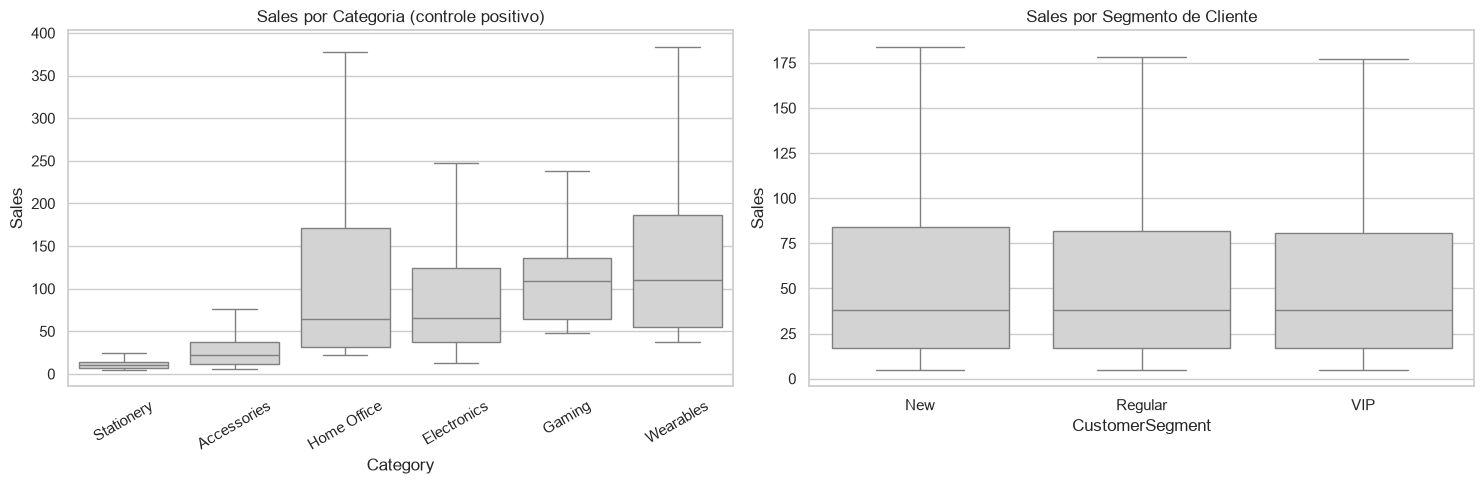

In [41]:
for grupo in ["Category", "CustomerSegment"]:
    amostras = [g["Sales"].values for _, g in df.groupby(grupo)]
    _, p_anova = stats.f_oneway(*amostras)
    _, p_kw = stats.kruskal(*amostras)
    print(f"Sales ~ {grupo:16s} | ANOVA p = {p_anova:.3g} | Kruskal-Wallis p = {p_kw:.3g}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ordem_cat = df.groupby("Category")["Sales"].median().sort_values().index
sns.boxplot(data=df, x="Category", y="Sales", order=ordem_cat, color=COR_NEUTRA, showfliers=False, ax=axes[0])
axes[0].set_title("Sales por Categoria (controle positivo)"); axes[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="CustomerSegment", y="Sales", order=["New", "Regular", "VIP"], color=COR_NEUTRA, showfliers=False, ax=axes[1])
axes[1].set_title("Sales por Segmento de Cliente")
plt.tight_layout(); plt.show()

In [42]:
# Se VIP não gasta mais POR PEDIDO, será que compra mais vezes ou gasta mais NO TOTAL?
clientes = df.groupby("CustomerID").agg(CustomerSegment=("CustomerSegment", "first"),
                                        n_pedidos=("OrderID", "size"), gasto_total=("Sales", "sum"))
print(clientes.groupby("CustomerSegment")[["n_pedidos", "gasto_total"]].median())
print("\nKruskal gasto_total ~ segmento: p =",
      round(stats.kruskal(*[g["gasto_total"] for _, g in clientes.groupby("CustomerSegment")]).pvalue, 4))

                 n_pedidos  gasto_total
CustomerSegment                        
New                    5.0        291.0
Regular                5.0        288.0
VIP                    5.0        298.0

Kruskal gasto_total ~ segmento: p = 0.4157


**Discussão:**

- Categoria: p ≈ 0 nos dois testes. O controle positivo funcionou, então o teste enxerga diferenças quando elas existem.
- Segmento: **não há diferença**. VIP, Regular e New têm a mesma mediana por pedido (38), o mesmo número de pedidos e o mesmo gasto total. O rótulo **"VIP" não corresponde a nenhum comportamento observável**. Ou o critério de segmentação vem de algo que não está na base, ou o rótulo foi atribuído aleatoriamente. Nos dois casos, `CustomerSegment` não deveria ser usado para decisão de negócio sem entender como é calculado.

#### Qualitativa x Qualitativa

Com ~49 mil linhas, o Qui-Quadrado pode dar p pequeno para associações irrelevantes. Por isso reportamos junto o **V de Cramér** (0 = nenhuma associação, 1 = associação total; abaixo de 0,1 é desprezível).

In [43]:
def cramers_v(tabela):
    chi2 = stats.chi2_contingency(tabela)[0]
    n = tabela.values.sum()
    return np.sqrt(chi2 / (n * (min(tabela.shape) - 1)))

res = []
for col in ["PaymentMethod", "City", "CustomerSegment", "Category", "ProductName", "Discount"]:
    t = pd.crosstab(df[col], df["desfecho"])
    p = stats.chi2_contingency(t)[1]
    taxa = pd.crosstab(df[col], df["desfecho"], normalize="index")["Problema"]
    res.append({"variavel": col, "p_valor_qui2": round(p, 4), "V_cramer": round(cramers_v(t), 4),
                "taxa_problema_min": f"{taxa.min():.1%}", "taxa_problema_max": f"{taxa.max():.1%}"})
pd.DataFrame(res).set_index("variavel")

,p_valor_qui2,V_cramer,taxa_problema_min,taxa_problema_max
variavel,,,,
PaymentMethod,0.9553,0.0026,7.9%,8.1%
City,0.1114,0.0171,6.7%,8.6%
CustomerSegment,0.3564,0.0065,7.8%,8.2%
Category,0.3943,0.0103,7.4%,8.6%
ProductName,0.0227,0.0260,6.5%,10.2%
Discount,0.3393,0.0107,7.6%,8.4%


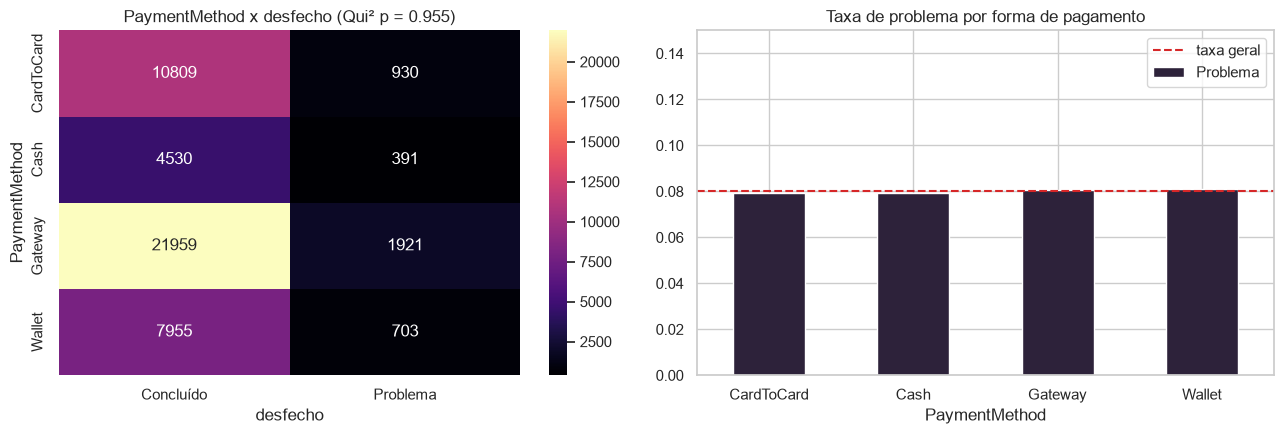

In [44]:
cont_pag = pd.crosstab(df["PaymentMethod"], df["desfecho"])
p_pag = stats.chi2_contingency(cont_pag)[1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cont_pag, annot=True, fmt="d", cmap="magma", ax=axes[0])
axes[0].set_title(f"PaymentMethod x desfecho (Qui² p = {p_pag:.3f})")
pd.crosstab(df["PaymentMethod"], df["desfecho"], normalize="index")["Problema"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].axhline(df["desfecho"].eq("Problema").mean(), color=COR_ALERTA, linestyle="--", label="taxa geral")
axes[1].set_ylim(0, 0.15); axes[1].set_title("Taxa de problema por forma de pagamento"); axes[1].legend()
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Discussão:** cinco das seis qualitativas não mostram associação com o desfecho (p > 0,05). A exceção é **`ProductName`** (p ≈ 0,02), onde a taxa de problema vai de ~6,5% a ~10,2% entre produtos. Esse é exatamente o caso em que o p-valor sozinho engana:

- o **V de Cramér é 0,026**, ou seja, associação desprezível;
- com ~49 mil linhas, o Qui-Quadrado detecta diferenças minúsculas;
- testamos 6 variáveis, e o produto tem 20 categorias. Com várias comparações, um p ≈ 0,02 isolado é bem possível por acaso (com correção de Bonferroni para 6 testes, o limite seria 0,05/6 ≈ 0,008 e ele não passaria).

Em resumo, **todos os V de Cramér ficam abaixo de 0,03**. Até pagamento em dinheiro (*Cash*), que num e-commerce real costuma ter mais cancelamento, tem a mesma taxa (~8%) que gateway ou carteira digital. Somando com os testes quantitativos: **nenhuma variável da base explica o desfecho do pedido.**

#### Dimensão temporal

A base cobre 30 meses. Duas perguntas: o volume é estável ao longo do tempo? Existe padrão por dia da semana?

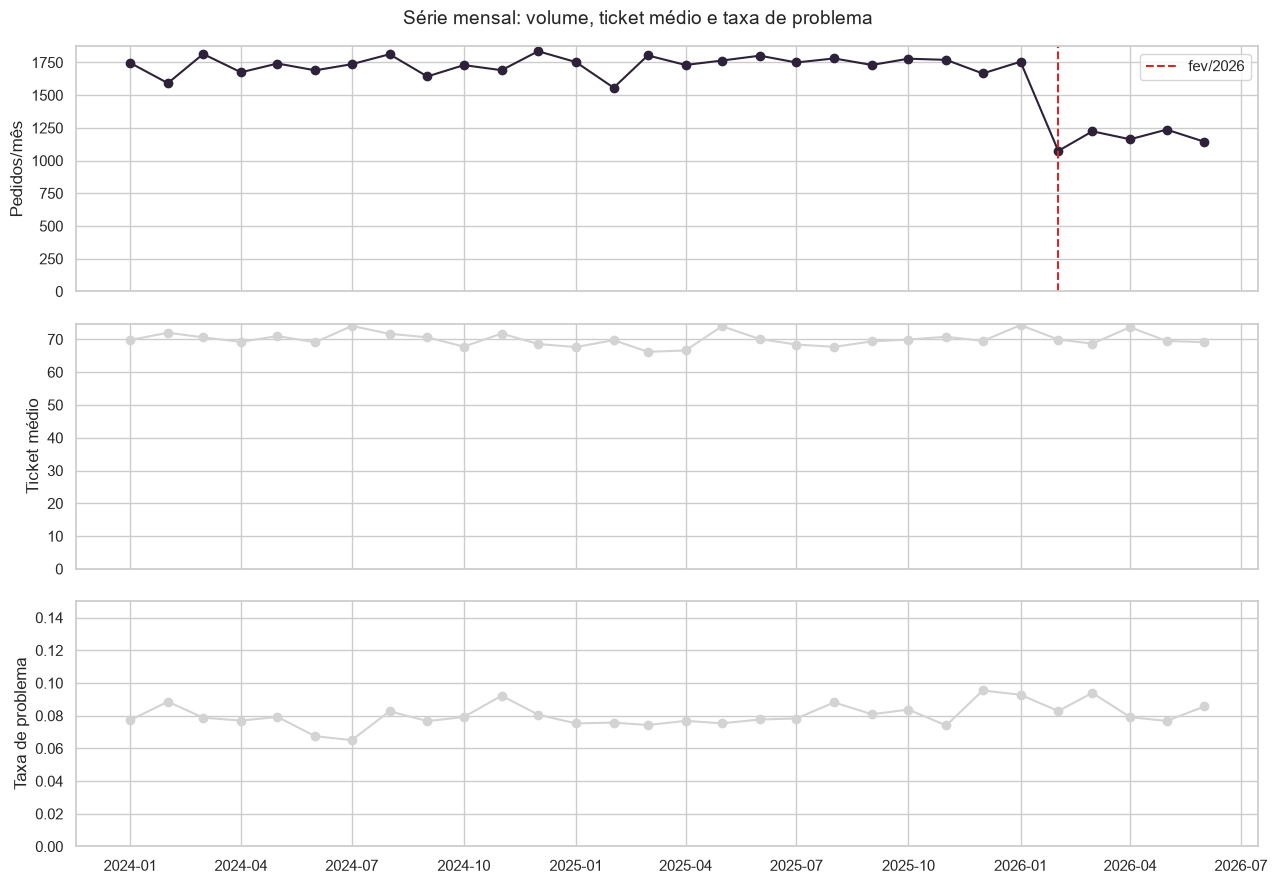

Média mensal jan/24–jan/26: 1734 | fev/26–jun/26: 1168 | queda: 33%


In [45]:
mensal = df.set_index("OrderDate").resample("MS").agg({"OrderID": "size", "Sales": "mean"})
mensal.columns = ["pedidos", "ticket_medio"]
mensal["taxa_problema"] = df.set_index("OrderDate")["desfecho"].eq("Problema").resample("MS").mean()

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].plot(mensal.index, mensal["pedidos"], color=COR_DESTAQUE, marker="o")
axes[0].axvline(pd.Timestamp("2026-02-01"), color=COR_ALERTA, linestyle="--", label="fev/2026")
axes[0].set_ylabel("Pedidos/mês"); axes[0].legend(); axes[0].set_ylim(0)
axes[1].plot(mensal.index, mensal["ticket_medio"], color=COR_NEUTRA, marker="o"); axes[1].set_ylabel("Ticket médio"); axes[1].set_ylim(0)
axes[2].plot(mensal.index, mensal["taxa_problema"], color=COR_NEUTRA, marker="o"); axes[2].set_ylabel("Taxa de problema"); axes[2].set_ylim(0, 0.15)
fig.suptitle("Série mensal: volume, ticket médio e taxa de problema", fontsize=14)
plt.tight_layout(); plt.show()

antes_q = mensal.loc[:"2026-01", "pedidos"].mean(); depois_q = mensal.loc["2026-02":, "pedidos"].mean()
print(f"Média mensal jan/24–jan/26: {antes_q:.0f} | fev/26–jun/26: {depois_q:.0f} | queda: {1 - depois_q / antes_q:.0%}")

Qui² de aderência (pedidos uniformes entre os dias?): p = 5.67e-44


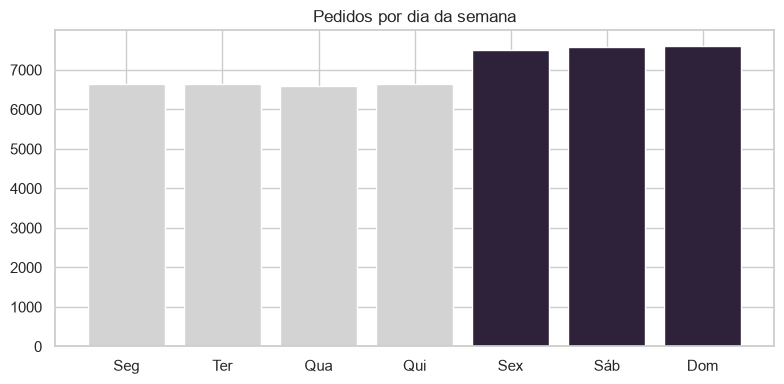

In [46]:
nomes = {0: "Seg", 1: "Ter", 2: "Qua", 3: "Qui", 4: "Sex", 5: "Sáb", 6: "Dom"}
por_dia = df["OrderDate"].dt.dayofweek.value_counts().sort_index()
qui2_dia = stats.chisquare(por_dia)
print(f"Qui² de aderência (pedidos uniformes entre os dias?): p = {qui2_dia.pvalue:.3g}")

cores = [COR_DESTAQUE if d >= 4 else COR_NEUTRA for d in por_dia.index]
plt.figure(figsize=(8, 4))
plt.bar([nomes[d] for d in por_dia.index], por_dia.values, color=cores)
plt.title("Pedidos por dia da semana")
plt.tight_layout(); plt.show()

**Discussão:**

- **Quebra estrutural em fev/2026:** o volume mensal cai ~33% de um mês para o outro e permanece baixo, enquanto ticket médio e taxa de problema continuam **estáveis**. Uma queda de demanda real costuma afetar o mix de produtos ou o ticket. Uma queda "limpa" só no volume sugere mudança na **coleta** (fonte parcial, amostragem diferente) ou dados ainda incompletos. **Comparações de volume entre 2025 e 2026 não são confiáveis** sem entender isso.
- **Dia da semana:** sexta, sábado e domingo têm ~14% mais pedidos que os demais dias (p ≈ 0, efeito claro). Um detalhe de domínio: o pico de sexta a domingo coincide com o **fim de semana ocidental**. No Irã, o descanso semanal é tradicionalmente centrado na sexta-feira, então o padrão merece investigação e pode ser mais um sinal de dados gerados sinteticamente.

#### Avaliação de Fairness

A base não tem sexo, mas tem dois atributos que em muitos contextos são sensíveis: **faixa etária** e **cidade** (região). A taxa de problema é homogênea entre esses grupos?

In [47]:
df["faixa_etaria"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 65], labels=["18-25", "26-35", "36-45", "46-55", "56-65"])
print("Desbalanceamento — faixa etária:\n", metrica_desbalanceamento(df["faixa_etaria"]))
print("\nDesbalanceamento — cidade:\n", metrica_desbalanceamento(df["City"]))

Desbalanceamento — faixa etária:
 n_classes                 5.000
razao_desbalanceamento    1.370
entropia_normalizada      0.997
dtype: float64

Desbalanceamento — cidade:
 n_classes                 10.000
razao_desbalanceamento     5.900
entropia_normalizada       0.926
dtype: float64


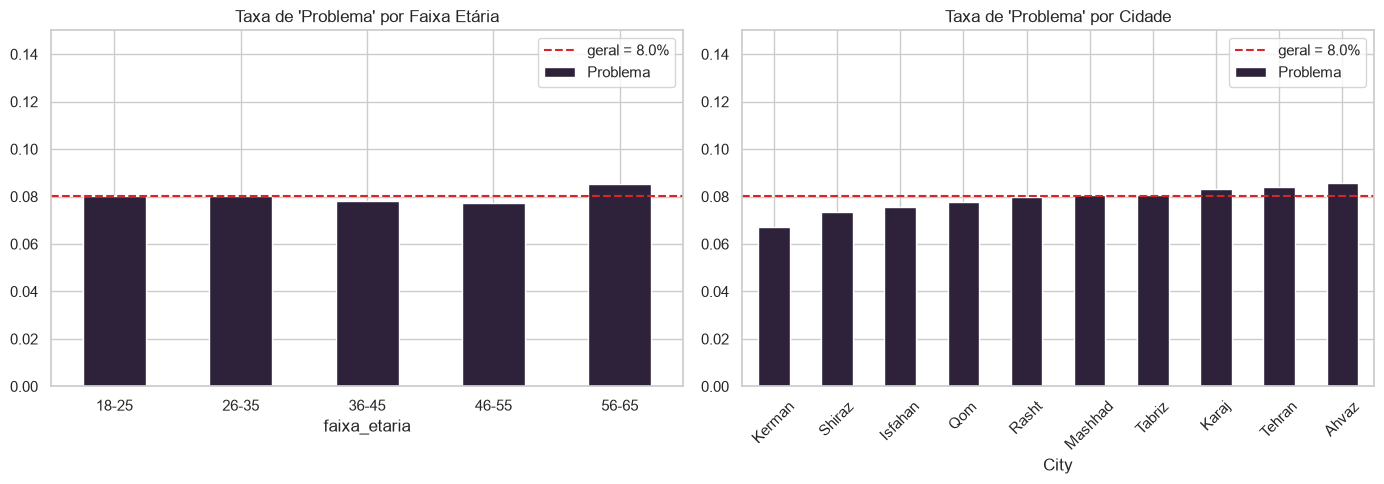

In [48]:
taxa_geral = df["desfecho"].eq("Problema").mean()
prop_faixa = pd.crosstab(df["faixa_etaria"], df["desfecho"], normalize="index")["Problema"]
prop_cidade = pd.crosstab(df["City"], df["desfecho"], normalize="index")["Problema"].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
prop_faixa.plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
prop_cidade.plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
for ax, titulo in zip(axes, ["Taxa de 'Problema' por Faixa Etária", "Taxa de 'Problema' por Cidade"]):
    ax.axhline(taxa_geral, color=COR_ALERTA, linestyle="--", label=f"geral = {taxa_geral:.1%}")
    ax.set_ylim(0, 0.15); ax.set_title(titulo); ax.legend(); ax.tick_params(axis="x", rotation=0 if "Faixa" in titulo else 45)
plt.tight_layout(); plt.show()

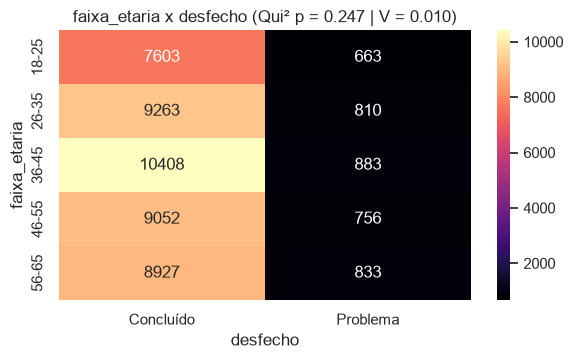

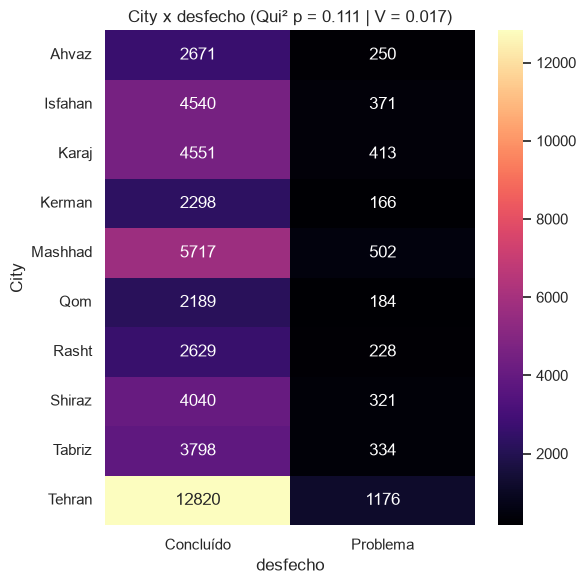

In [49]:
for atributo in ["faixa_etaria", "City"]:
    t = pd.crosstab(df[atributo], df["desfecho"])
    chi2, p, gl, _ = stats.chi2_contingency(t)
    fig, ax = plt.subplots(figsize=(6, 0.45 * len(t) + 1.5))
    sns.heatmap(t, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x desfecho (Qui² p = {p:.3f} | V = {cramers_v(t):.3f})")
    plt.tight_layout(); plt.show()

**Análise de sensibilidade:** a faixa 36–45 contém o pico de idade imputada (41). Se a imputação estivesse "escondendo" um padrão, o resultado mudaria sem esses clientes.

In [50]:
t_com = pd.crosstab(df["faixa_etaria"], df["desfecho"])
t_sem = pd.crosstab(df.loc[~df["idade_41"], "faixa_etaria"], df.loc[~df["idade_41"], "desfecho"])
print(f"Qui² faixa etária — com idade 41: p = {stats.chi2_contingency(t_com)[1]:.3f}")
print(f"Qui² faixa etária — sem idade 41: p = {stats.chi2_contingency(t_sem)[1]:.3f}")

Qui² faixa etária — com idade 41: p = 0.247
Qui² faixa etária — sem idade 41: p = 0.210


**Discussão:** a taxa de problema oscila entre ~7,7% e ~8,5% por faixa etária e entre ~6,7% e ~8,6% por cidade, sem significância estatística e com V de Cramér desprezível. **O resultado não muda** ao excluir os clientes de idade 41, então a imputação não está mascarando nada.

Na ótica de fairness, isso é paridade entre grupos. **Mas cuidado com a leitura:** aqui a paridade não indica uma operação justa. Ela é o mesmo sintoma visto em todas as outras variáveis: **o desfecho não se relaciona com nada**. Paridade num dataset sem sinal não diz nada sobre equidade. Seria um erro citar este resultado como "prova" de que a empresa trata todos os grupos igualmente.

#### Outliers bivariados

Na aula, a pergunta era se algum ponto parece normal em cada variável isoladamente e se destaca na combinação. Aqui temos o caso perfeito: `OrderDate` e `SignupDate` estão, **individualmente**, dentro de faixas totalmente plausíveis. Só a combinação revela o problema.

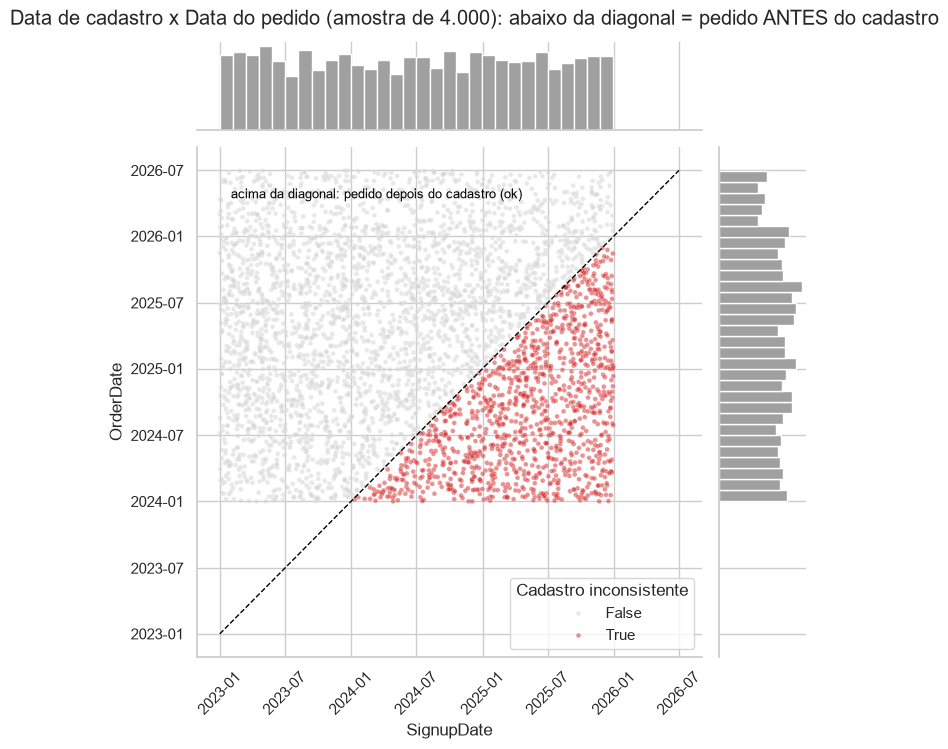

In [51]:
amostra_datas = df.sample(4000, random_state=1)
g = sns.JointGrid(data=amostra_datas, x="SignupDate", y="OrderDate", height=7)
g.plot_joint(sns.scatterplot, hue=amostra_datas["cadastro_inconsistente"],
             palette={False: COR_NEUTRA, True: COR_ALERTA}, alpha=0.5, s=12)
g.plot_marginals(sns.histplot, color="gray", bins=30)   # marginais sem separar: cada data sozinha parece normal
lim = [pd.Timestamp("2023-01-01"), pd.Timestamp("2026-07-01")]
g.ax_joint.plot(lim, lim, color="black", linestyle="--", linewidth=1)
g.ax_joint.text(pd.Timestamp("2023-02-01"), pd.Timestamp("2026-04-15"), "acima da diagonal: pedido depois do cadastro (ok)",
                color="black", fontsize=9)
g.ax_joint.legend(title="Cadastro inconsistente", loc="lower right")
g.ax_joint.tick_params(axis="x", rotation=45)
plt.suptitle("Data de cadastro x Data do pedido (amostra de 4.000): abaixo da diagonal = pedido ANTES do cadastro", y=1.02)
plt.show()

**Discussão:** os histogramas marginais (em cinza) mostram as duas datas **uniformes** e sem nada de estranho. No plano conjunto, porém, todo ponto **abaixo da diagonal** é impossível (compra antes do cadastro), e é uma faixa inteira do gráfico, não pontos isolados. A distribuição uniforme e sem relação entre as duas datas indica que foram geradas de forma **independente**, e não "pedido sempre depois do cadastro" como a lógica de negócio exigiria.

#### Análise Multivariada

##### Matriz de Correlação

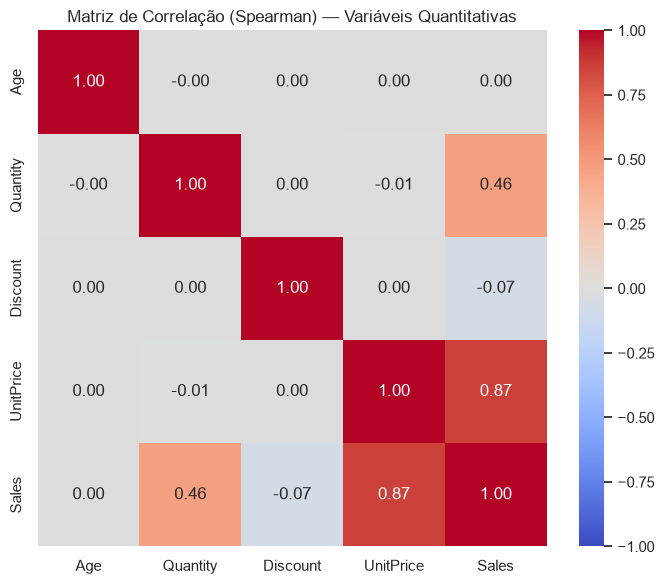

In [52]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout(); plt.show()

**Como interpretar:** |r| < 0,3 é fraca; entre 0,3 e 0,7, moderada; acima de 0,7, forte.

Há uma correlação forte (`UnitPrice`–`Sales`) e uma moderada (`Quantity`–`Sales`), ambas explicadas pela fórmula de cálculo. Não há redundância "escondida" entre variáveis independentes. A única redundância real era `OrderValue`, já removida.

##### Correlograma

Uma diferença em relação ao correlograma da aula: lá o círculo usava `np.corrcoef` (**Pearson**), enquanto a matriz logo antes era Spearman. Para manter a coerência com a decisão da Seção 3, aqui o triângulo superior usa **Spearman**. Também usamos amostra de 4.000 no triângulo inferior, para os scatters serem legíveis.

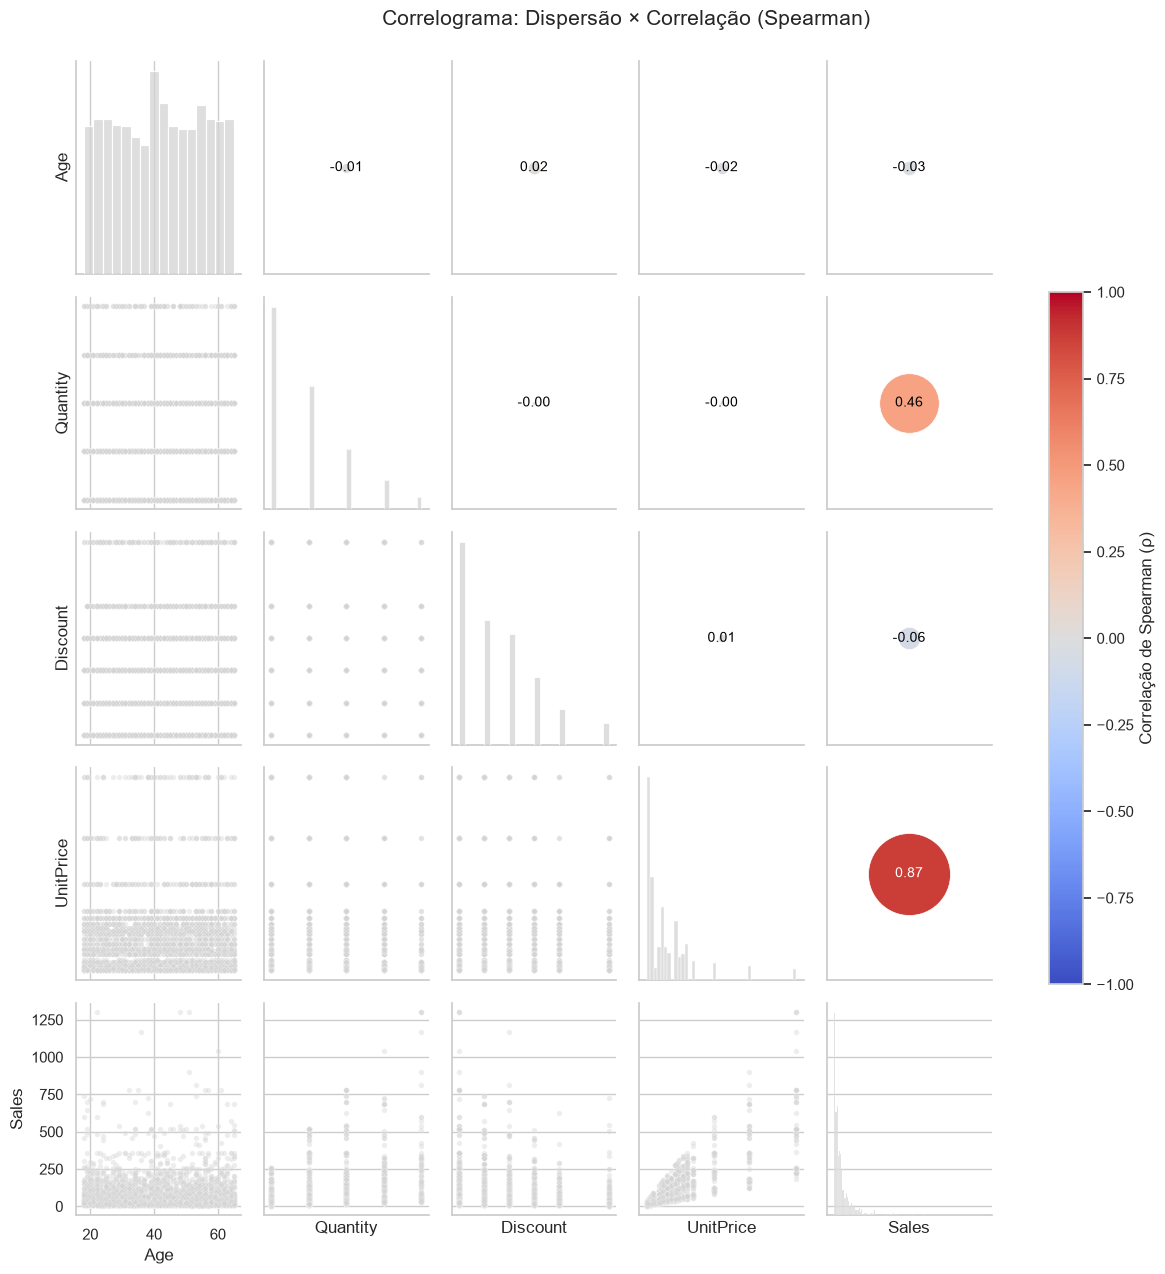

In [53]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = stats.spearmanr(x, y).statistic
    ax = plt.gca()
    ax.scatter([0.5], [0.5], s=abs(r) * 4000, c=[r], cmap="coolwarm", vmin=-1, vmax=1,
               transform=ax.transAxes, edgecolor="white", linewidth=0.5)
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes, ha="center", va="center",
                fontsize=10, color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT].sample(4000, random_state=42), diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.4, s=15)
g.map_diag(sns.histplot, color=COR_NEUTRA)
g.map_upper(circulo_correlacao)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm"); sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman (ρ)")
g.fig.suptitle("Correlograma: Dispersão × Correlação (Spearman)", y=1.02, fontsize=15)
plt.show()

## 7. Principais Conclusões

1. **"Clean" não significa "correto".** Sem nenhum `NaN` e sem duplicadas, a base ainda tinha 24 quantidades negativas ou zeradas com status "concluído", uma coluna inteira redundante (`OrderValue`), ~150 clientes com idade provavelmente imputada pela mediana (41), **28% dos pedidos com data de cadastro posterior à compra** e um produto com preço incompatível com a categoria (Monitor a 21). Os IDs mostram que 778 pedidos e 180 clientes já tinham sido removidos por uma limpeza que não conhecemos.

2. **Nenhuma variável explica o pedido dar problema.** Valor, quantidade, desconto, preço, idade, cidade, forma de pagamento, categoria, produto e segmento: nenhuma com associação relevante (V de Cramér < 0,03 em todas; o único p < 0,05, em `ProductName`, não resiste à correção para múltiplos testes). Com ~49 mil pedidos, os testes tinham poder para detectar efeitos mínimos, então isso é ausência de relação, não falta de amostra.

3. **O valor do pedido é explicado pela aritmética, não pelo cliente.** `Sales` é função determinística de preço × quantidade × desconto, com cauda longa (média ≈ 70, mediana = 38). Quem o cliente é (idade, cidade, segmento) não altera o quanto ele gasta. O rótulo **VIP é vazio**: mesmo ticket, mesma frequência e mesmo gasto total que clientes novos.

4. **O tempo carrega dois padrões e um alerta.** Há mais pedidos de sexta a domingo, e o volume **cai ~33% a partir de fev/2026** com ticket e taxa de problema intactos, o que sugere mudança na coleta, e não na demanda.

5. **A base tem fortes indícios de ser sintética**, e isso define para que ela serve. Idade uniforme de 18 a 65, desconto sem efeito em quantidade, datas de cadastro sorteadas independentemente das compras e paridade perfeita em todos os subgrupos são padrões improváveis em dados reais. **Ela serve bem para praticar técnicas de EDA, mas não para modelagem preditiva do desfecho nem para conclusões de negócio ou de fairness.**

## 8. Declaração de Uso de IA


**Ferramenta utilizada:** Claude (Anthropic), via chat, com execução de código Python para explorar o dataset antes de montar o notebook.

**Para o que foi aplicada:**

| Etapa | Uso da IA |
|---|---|
| Leitura da atividade | Resumo do roteiro da aula prática e dos pontos do template que não deveriam ser copiados sem adaptação |
| Exploração do dataset | Checagens de integridade (fórmula de `Sales`, consistência cliente/produto, buracos nos IDs, datas), testes estatísticos e padrões temporais |
| Código | Geração das células de análise e visualização, reaproveitando a estrutura, as cores e as funções auxiliares da aula |
| Redação | Rascunho das discussões e conclusões a partir dos resultados das células executadas |

**Adaptações feitas em relação ao template da aula (para você confirmar se concorda):**

- **Normalidade:** o Shapiro-Wilk da aula não é confiável com n ≈ 49 mil. Foi substituído por Shapiro em subamostra de 5.000 **mais** Anderson-Darling na base completa.
- **Histogramas por classe em densidade:** com desbalanceamento 92/8, a contagem deixaria a classe "Problema" ilegível.
- **Amostragem nos gráficos de dispersão e no correlograma** (4.000 pontos) e eixos em log para `Sales`.
- **Correlograma com Spearman** em vez do Pearson do template, por coerência com os testes de normalidade.
- **V de Cramér junto do Qui-Quadrado:** com n grande, só o p-valor poderia indicar associações irrelevantes.

**Decisões de tratamento que valem sua avaliação crítica:**

- Remover só as 24 linhas com `Quantity` ≤ 0 e **manter** os outliers estatísticos de `Sales`, `UnitPrice` e `Quantity`.
- **Não** remover os 28% de pedidos com cadastro inconsistente (sinalizar em vez de excluir).
- **Não** corrigir o preço do Monitor, apesar da hipótese de "zero perdido", por falta de acesso à fonte.
- Tratar a idade 41 como imputação provável e verificar com análise de sensibilidade, em vez de remover.

**O que foi aceito / modificado / rejeitado, e por quê:** *(preencher com a sua revisão)*

---
> 🆕 **NOVA SEÇÃO (não estava no notebook da Aula 11)** — as células abaixo servem apenas para salvar os datasets em disco.

## 🆕 Download dos Datasets

Vamos salvar duas versões do dataset:

- `data/raw/dataset.csv`: o dataset **original**, exatamente como foi lido (`df_original`).
- `data/clean/dataset.csv`: o dataset **tratado** (estado final do `df`): sem os 24 pedidos com `Quantity` ≤ 0, sem a coluna redundante `OrderValue`, e com as colunas derivadas da EDA (`desfecho`, `cadastro_inconsistente`, `idade_41`, `produto_suspeito`, `Sales_log`, `faixa_etaria`). É esse arquivo que o `app.py` lê.

In [54]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [55]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL
df_original.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_original.shape[0]} linhas x {df_original.shape[1]} colunas")

Raw salvo em ..\data\raw\dataset.csv — 49222 linhas x 17 colunas


In [56]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_original.shape[0] - df.shape[0]}")

Clean salvo em ..\data\clean\dataset.csv — 49198 linhas x 22 colunas
Linhas removidas no tratamento: 24
